# IE7275 Group Project 1: Personalized product recommendation on Amazon Reviews 2023 (Video Games)
**Devansh Nayak, Rishi Hirpara, Venkatashivasai Muppidi**

We build and compare eight recommenders, from a popularity baseline to a transformer, on one dataset with one shared evaluation protocol:
popularity, item-item KNN, ALS and BPR matrix factorization, SVD (rating prediction), neural collaborative filtering (NeuMF), SASRec, and a content-based hybrid.
One scoring variant of the trained ALS, `als+history`, is reported next to it (see the ALS section for why).

**This notebook is self-contained.** The first cells write the whole `recsys` package (data loading, metrics, evaluation harness, every model) to disk, so it needs only
this file and the `data/` and `results/` folders next to it. All numbers below are read from the saved result files produced by those same models, unless `RETRAIN = True`.

In [1]:
# Switches
RETRAIN = False         # False: read the saved results in results/.  True: refit every final model (roughly an hour on a laptop).
RUN_PREPROCESS = False  # True: rebuild data/processed from the raw Amazon files in data/raw (a 3 GB download; see the data section).

import json, os, sys, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
os.makedirs("recsys/models", exist_ok=True)

## 0. The source code
Each cell below writes one module of the package. They are shown in dependency order and are the exact code that produced every result in this notebook.

In [2]:
%%writefile recsys/__init__.py
"""IE7275 Group Project 1: shared recommender-system framework."""

Writing recsys/__init__.py


In [3]:
%%writefile recsys/config.py
"""Constants shared by every model and by the evaluation harness. Do not override locally."""
import os
import random
from pathlib import Path

import numpy as np

ROOT = Path(__file__).resolve().parent.parent

# RECSYS_DATA_DIR lets you point at a different processed dataset (e.g. data/processed_dev).
DATA_DIR = Path(os.environ.get("RECSYS_DATA_DIR", ROOT / "data" / "processed"))

# Results from a non-default dataset go to their own folder so they never mix with real results.
RESULTS_DIR = ROOT / "results" if DATA_DIR.name == "processed" else ROOT / "results" / DATA_DIR.name

SEED = 42
K_CORE = 5
K_LIST = (5, 10, 20)
PRIMARY_METRIC = "ndcg@10"  # use this one for model selection and early stopping

# Cold-start experiment: a fixed share of users is held out of training entirely ("new users"),
# then only their first n purchases are revealed to the model.
COLD_FRAC = 0.1
COLD_REVEAL = (0, 1, 2, 3)


def get_device() -> str:
    """'mps' on Apple Silicon, 'cuda' if present, else 'cpu'."""
    import torch

    if torch.backends.mps.is_available():
        return "mps"
    if torch.cuda.is_available():
        return "cuda"
    return "cpu"


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch

        torch.manual_seed(seed)
    except ImportError:
        pass

Writing recsys/config.py


In [4]:
%%writefile recsys/data.py
"""Loading the processed dataset. Every model must get its data through load(); never re-read raw files."""
import hashlib
import json
from dataclasses import dataclass
from functools import cached_property
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

from recsys.config import DATA_DIR

INTERACTION_DTYPES = {
    "user_idx": "int32",
    "item_idx": "int32",
    "rating": "float32",
    "timestamp": "int64",
}


def fingerprint(train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame) -> str:
    """Short hash of the three splits. Stored in meta.json and in every results file."""
    h = hashlib.sha256()
    for part in (train, val, test):
        h.update(part["user_idx"].to_numpy().tobytes())
        h.update(part["item_idx"].to_numpy().tobytes())
    return h.hexdigest()[:12]


def build_histories(frames: list[pd.DataFrame], n_users: int) -> list[np.ndarray]:
    """Per-user chronological item arrays (index = user_idx).

    Frames are concatenated in order, and rows keep their file order within a user, so
    build_histories([train, val]) puts the validation item last for every user.
    """
    df = pd.concat(frames, ignore_index=True)
    users = df["user_idx"].to_numpy()
    items = df["item_idx"].to_numpy()
    order = np.argsort(users, kind="stable")
    counts = np.bincount(users, minlength=n_users)
    return np.split(items[order], np.cumsum(counts)[:-1])


def to_csr(df: pd.DataFrame, n_users: int, n_items: int, values: str = "implicit") -> sp.csr_matrix:
    """User x item sparse matrix with the full catalog shape.

    values='implicit' gives 1.0 per interaction, values='rating' gives the star rating.
    """
    v = np.ones(len(df), dtype=np.float32) if values == "implicit" else df["rating"].to_numpy(np.float32)
    return sp.csr_matrix((v, (df["user_idx"].to_numpy(), df["item_idx"].to_numpy())), shape=(n_users, n_items))


@dataclass(eq=False)
class SplitData:
    train: pd.DataFrame  # user_idx, item_idx, rating, timestamp; sorted by user then time
    val: pd.DataFrame  # exactly one row per user: second-to-last interaction
    test: pd.DataFrame  # exactly one row per user: last interaction
    users: pd.DataFrame  # user_idx, user_id, n_train, activity_bin
    items: pd.DataFrame  # item_idx, parent_asin, title, ..., n_train, pop_bin
    meta: dict
    # Only in the cold-start dataset (data/processed_coldstart): the held-out "new users" and the
    # train-period rows that were removed from `train` for them.
    new_users: np.ndarray | None = None
    new_interactions: pd.DataFrame | None = None

    @property
    def n_users(self) -> int:
        return self.meta["n_users"]

    @property
    def n_items(self) -> int:
        return self.meta["n_items"]

    @property
    def data_version(self) -> str:
        return self.meta["data_version"]

    @cached_property
    def train_history(self) -> list[np.ndarray]:
        """What a model may condition on when predicting the validation item."""
        return build_histories([self.train], self.n_users)

    @cached_property
    def trainval_history(self) -> list[np.ndarray]:
        """What a model may condition on when predicting the test item."""
        return build_histories([self.train, self.val], self.n_users)

    @cached_property
    def item_train_count(self) -> np.ndarray:
        return self.items["n_train"].to_numpy()

    @cached_property
    def eval_users(self) -> np.ndarray:
        """Users scored in the standard val/test evaluation: everyone, except the new users in a cold-start dataset."""
        if self.new_users is None:
            return np.arange(self.n_users)
        return np.setdiff1d(np.arange(self.n_users), self.new_users)

    @cached_property
    def new_user_history(self) -> list[np.ndarray]:
        """Each new user's full chronological sequence before the test item (empty array for everyone else)."""
        if self.new_users is None:
            raise ValueError("this is not a cold-start dataset")
        val_rows = self.val[self.val["user_idx"].isin(self.new_users)]
        return build_histories([self.new_interactions, val_rows], self.n_users)


def _check(name: str, df: pd.DataFrame) -> None:
    for col, dtype in INTERACTION_DTYPES.items():
        if col not in df.columns or str(df[col].dtype) != dtype:
            raise ValueError(f"{name}.parquet: column {col!r} must be {dtype}, got {df.get(col, pd.Series()).dtype}")


def load(data_dir: str | Path | None = None) -> SplitData:
    d = Path(data_dir) if data_dir else DATA_DIR
    meta = json.loads((d / "meta.json").read_text())
    frames = {n: pd.read_parquet(d / f"{n}.parquet") for n in ("train", "val", "test")}
    for n, df in frames.items():
        _check(n, df)

    n_users, n_items = meta["n_users"], meta["n_items"]
    for n in ("val", "test"):
        u = frames[n]["user_idx"].to_numpy()
        if len(u) != n_users or not np.array_equal(u, np.arange(n_users)):
            raise ValueError(f"{n}.parquet must hold exactly one row per user, ordered by user_idx")
    for n, df in frames.items():
        if df["item_idx"].max() >= n_items or df["item_idx"].min() < 0:
            raise ValueError(f"{n}.parquet: item_idx outside [0, n_items)")

    found = fingerprint(frames["train"], frames["val"], frames["test"])
    if found != meta["data_version"]:
        raise ValueError(f"data files do not match meta.json (found {found}, expected {meta['data_version']}); "
                         "restore the data folder from the original copy instead of editing it")

    users = pd.read_parquet(d / "users.parquet")
    items = pd.read_parquet(d / "items.parquet")
    if len(items) != n_items or len(users) != n_users:
        raise ValueError("users.parquet / items.parquet disagree with meta.json")

    new_users = new_inter = None
    if (d / "new_users.parquet").exists():
        new_users = pd.read_parquet(d / "new_users.parquet")["user_idx"].to_numpy()
        new_inter = pd.read_parquet(d / "new_user_interactions.parquet")
        _check("new_user_interactions", new_inter)
        if np.isin(frames["train"]["user_idx"].to_numpy(), new_users).any():
            raise ValueError("new users must have no rows in train.parquet")
    return SplitData(frames["train"], frames["val"], frames["test"], users, items, meta, new_users, new_inter)

Writing recsys/data.py


In [5]:
%%writefile recsys/metrics.py
"""The only metric implementations in the project. Models must never compute their own.

Protocol: each user has ONE held-out target item. The model scores the full catalog, items in the
user's history are removed from the ranking, and we record the rank of the target (1 = best).
Every ranking metric below is a function of that rank.

Ties: rank = 1 + number of other candidate items with score >= the target's score. A model that
returns identical scores for everything therefore gets the worst possible rank, not a lucky one.
Because there is a single relevant item, recall@k equals hit rate@k, and precision@k and f1@k are
deterministic functions of it, so they carry no independent information.
"""
import numpy as np

from recsys.config import K_LIST


def mask_history(scores: np.ndarray, histories: list[np.ndarray]) -> None:
    """In place: set the score of every already-seen item to -inf."""
    lens = np.fromiter((len(h) for h in histories), dtype=np.int64, count=len(histories))
    if lens.sum() == 0:
        return
    rows = np.repeat(np.arange(len(histories)), lens)
    cols = np.concatenate(histories)
    scores[rows, cols] = -np.inf


def target_ranks(scores: np.ndarray, targets: np.ndarray) -> np.ndarray:
    """1-based rank of each row's target item, pessimistic on ties. scores: [B, n_items]."""
    if np.isnan(scores).any():
        raise ValueError("model.score() returned NaN")
    target_score = scores[np.arange(len(targets)), targets]
    return (scores >= target_score[:, None]).sum(axis=1).astype(np.int32)


def topk_items(scores: np.ndarray, k: int) -> np.ndarray:
    """Top-k item indices per row, best first. Order among exactly tied scores is unspecified."""
    part = np.argpartition(-scores, k - 1, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(scores, part, axis=1), axis=1, kind="stable")
    return np.take_along_axis(part, order, axis=1).astype(np.int32)


def ranking_metrics(ranks: np.ndarray, ks=K_LIST) -> dict[str, float]:
    out = {}
    for k in ks:
        hit = (ranks <= k).astype(np.float64)
        precision = hit / k
        recall = hit
        denom = precision + recall
        f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(denom), where=denom > 0)
        ndcg = np.where(ranks <= k, 1.0 / np.log2(ranks + 1.0), 0.0)
        out[f"precision@{k}"] = float(precision.mean())
        out[f"recall@{k}"] = float(recall.mean())
        out[f"f1@{k}"] = float(f1.mean())
        out[f"ndcg@{k}"] = float(ndcg.mean())
    out["mrr"] = float((1.0 / ranks).mean())
    return out


def rating_metrics(pred: np.ndarray, true: np.ndarray) -> dict[str, float]:
    """Predictions are clipped to the 1-5 star range before scoring."""
    err = np.clip(pred, 1.0, 5.0) - true
    return {"rmse": float(np.sqrt(np.mean(err**2))), "mae": float(np.mean(np.abs(err)))}


def _gini(counts: np.ndarray) -> float:
    c = np.sort(counts.astype(np.float64))
    n, total = len(c), c.sum()
    if total == 0:
        return 0.0
    return float(2 * np.sum(np.arange(1, n + 1) * c) / (n * total) - (n + 1) / n)


def beyond_accuracy(topk: np.ndarray, n_items: int, item_train_count: np.ndarray, ks=K_LIST) -> dict[str, float]:
    """Diversity / popularity-bias measures over the recommended lists of all evaluated users.

    coverage@k : share of the catalog that appears in at least one user's top-k
    novelty@k  : mean of -log2(p(item)) over recommended items, p = train count / total train
                 interactions (items with zero train count use a count of 1)
    avg_pop@k  : mean train interaction count of the recommended items
    gini@k     : Gini index of how often each item is recommended (0 = even, 1 = one item only)
    """
    total = max(int(item_train_count.sum()), 1)
    p = np.maximum(item_train_count, 1) / total
    info = -np.log2(p)
    out = {}
    for k in ks:
        top = topk[:, :k]
        out[f"coverage@{k}"] = float(len(np.unique(top)) / n_items)
        out[f"novelty@{k}"] = float(info[top].mean())
        out[f"avg_pop@{k}"] = float(item_train_count[top].mean())
        out[f"gini@{k}"] = _gini(np.bincount(top.ravel(), minlength=n_items))
    return out

Writing recsys/metrics.py


In [6]:
%%writefile recsys/sampling.py
"""Negative sampling shared by the models that train on sampled negatives (BPR, NeuMF, SASRec)."""
import numpy as np


def interaction_keys(users: np.ndarray, items: np.ndarray, n_items: int) -> np.ndarray:
    """Sorted integer keys user * n_items + item of every known interaction, for fast membership tests."""
    return np.sort(users.astype(np.int64) * n_items + items.astype(np.int64))


def sample_negatives(rng: np.random.Generator, users: np.ndarray, n_items: int, sorted_keys: np.ndarray) -> np.ndarray:
    """One uniformly random item per entry of `users`, never an item that user has in `sorted_keys` (rejection sampling)."""
    users = users.astype(np.int64)
    neg = rng.integers(0, n_items, size=len(users))
    bad = _known(sorted_keys, users * n_items + neg)
    while bad.any():
        idx = np.flatnonzero(bad)
        neg[idx] = rng.integers(0, n_items, size=len(idx))
        bad[idx] = _known(sorted_keys, users[idx] * n_items + neg[idx])
    return neg


def _known(sorted_keys: np.ndarray, keys: np.ndarray) -> np.ndarray:
    pos = np.minimum(np.searchsorted(sorted_keys, keys), len(sorted_keys) - 1)
    return sorted_keys[pos] == keys

Writing recsys/sampling.py


In [7]:
%%writefile recsys/models/__init__.py
"""One module per recommender; recsys/models/base.py defines the interface they implement."""

Writing recsys/models/__init__.py


In [8]:
%%writefile recsys/models/base.py
"""The interface every model implements. Copy recsys/models/popularity.py as a starting point."""
import pickle
from abc import ABC, abstractmethod
from pathlib import Path

import numpy as np

from recsys.data import SplitData
from recsys.metrics import mask_history, topk_items


class Recommender(ABC):
    # Must equal the file name, e.g. recsys/models/knn.py -> name = "knn".
    name: str = ""
    # True only if predict() returns star-rating estimates (enables RMSE/MAE).
    supports_rating: bool = False

    def __init__(self, **config):
        # Hyperparameters only, JSON-serialisable. Saved into the results file.
        self.config = config

    @abstractmethod
    def fit(self, data: SplitData) -> None:
        """Train on data.train. data.val may be used for early stopping or tuning, never data.test."""

    @abstractmethod
    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        """Scores for the FULL catalog: numpy float32 array of shape [len(user_idxs), n_items], higher = better.

        histories[i] is the chronological item_idx array the model may condition on for user_idxs[i]
        (train items when evaluating validation, train+val items when evaluating test). Models that
        learn a vector per user at fit time may ignore it; sequence and neighbourhood models use it.
        Do not mask the history yourself, the harness does that. Must be callable at any point after
        fit() has started producing a usable model, so it can be used for early stopping.
        """

    def predict(self, user_idxs: np.ndarray, item_idxs: np.ndarray) -> np.ndarray:
        """Star-rating estimates for (user, item) pairs. Only needed if supports_rating is True."""
        raise NotImplementedError

    def num_parameters(self) -> int | None:
        """Trainable parameter count for the cost table, or None if not meaningful."""
        return None

    def recommend(self, user_idx: int, k: int = 10, history: np.ndarray | None = None) -> list[int]:
        """Top-k item_idx for one user, excluding their history. Used by the demo."""
        history = np.asarray([] if history is None else history, dtype=np.int64)
        scores = np.array(self.score(np.array([user_idx]), [history]), dtype=np.float32)
        mask_history(scores, [history])
        return topk_items(scores, k)[0].tolist()

    def save(self, path) -> None:
        """Pickle the fitted model (torch networks are moved to the CPU first) so it can be reloaded without retraining."""
        net, dev = getattr(self, "net", None), getattr(self, "dev", None)
        if net is not None:
            net.to("cpu")
            self.dev = "cpu"
        try:
            Path(path).parent.mkdir(parents=True, exist_ok=True)
            with open(path, "wb") as f:
                pickle.dump(self, f, protocol=pickle.HIGHEST_PROTOCOL)
        finally:
            if net is not None:
                net.to(dev)
                self.dev = dev

    @staticmethod
    def load(path) -> "Recommender":
        """Reload a model saved with save(); torch networks go to the best available device."""
        from recsys.config import get_device

        with open(path, "rb") as f:
            model = pickle.load(f)
        if getattr(model, "net", None) is not None:
            model.dev = get_device()
            model.net.to(model.dev)
        return model

Writing recsys/models/base.py


In [9]:
%%writefile recsys/harness.py
"""Evaluation harness shared by every model.

evaluate(model, data, split) is cheap enough to call inside a training loop for early stopping.
run_experiment(model, data) is what recsys.run calls: fit, evaluate val + test, write results.

On the cold-start dataset (data/processed_coldstart) run_experiment also scores the new users:
the model is shown only the first n purchases of each new user and must rank their last purchase.
The candidate list excludes all of the user's other purchases for every n, so the target and the
candidates are identical across n and only the information given to the model changes.
"""
import json
import os
import time
from dataclasses import dataclass
from datetime import datetime

import numpy as np
import pandas as pd

from recsys.config import COLD_REVEAL, K_LIST, RESULTS_DIR, SEED, get_device, set_seed
from recsys.data import SplitData
from recsys.metrics import beyond_accuracy, mask_history, rating_metrics, ranking_metrics, target_ranks, topk_items
from recsys.models.base import Recommender


@dataclass
class SplitOutput:
    users: np.ndarray  # user_idx evaluated
    ranks: np.ndarray  # rank of the target item per user, 1 = best
    topk: np.ndarray  # [n_users, max(K_LIST)] recommended item_idx
    rating_pred: np.ndarray | None
    score_seconds: float


def _eval_users(data: SplitData, max_users: int | None, pool: np.ndarray | None = None) -> np.ndarray:
    pool = data.eval_users if pool is None else pool
    if max_users is None or max_users >= len(pool):
        return pool
    rng = np.random.default_rng(SEED)
    return np.sort(rng.choice(pool, size=max_users, replace=False))


def _score_and_rank(model: Recommender, data: SplitData, users: np.ndarray, targets: np.ndarray,
                    model_hist: list, mask_hist: list, batch_size: int) -> SplitOutput:
    """model_hist is what the model sees, mask_hist is removed from the candidate list. Both indexed by user_idx."""
    ranks = np.empty(len(users), dtype=np.int32)
    topk = np.empty((len(users), max(K_LIST)), dtype=np.int32)
    score_seconds = 0.0
    for start in range(0, len(users), batch_size):
        batch = users[start : start + batch_size]
        t0 = time.perf_counter()
        raw = model.score(batch, [model_hist[u] for u in batch])
        score_seconds += time.perf_counter() - t0
        if not isinstance(raw, np.ndarray):
            raise TypeError("model.score() must return a numpy array (call .cpu().numpy() on torch tensors)")
        if raw.shape != (len(batch), data.n_items):
            raise ValueError(f"model.score() returned {raw.shape}, expected {(len(batch), data.n_items)}")
        scores = np.array(raw, dtype=np.float32, copy=True)  # copy: masking must not touch model state
        mask_history(scores, [mask_hist[u] for u in batch])
        sl = slice(start, start + len(batch))
        ranks[sl] = target_ranks(scores, targets[batch])
        topk[sl] = topk_items(scores, max(K_LIST))
    return SplitOutput(users, ranks, topk, None, score_seconds)


def run_split(model: Recommender, data: SplitData, split: str, batch_size: int = 1024, max_users: int | None = None) -> SplitOutput:
    if split not in ("val", "test"):
        raise ValueError("split must be 'val' or 'test'")
    target_df = data.val if split == "val" else data.test
    histories = data.train_history if split == "val" else data.trainval_history
    targets = target_df["item_idx"].to_numpy()
    users = _eval_users(data, max_users)

    out = _score_and_rank(model, data, users, targets, histories, histories, batch_size)
    if model.supports_rating:
        out.rating_pred = np.asarray(model.predict(users, targets[users]), dtype=np.float64)
    return out


def run_new_users(model: Recommender, data: SplitData, n_revealed: int, batch_size: int = 1024, max_users: int | None = None) -> SplitOutput:
    """Cold-start evaluation: show the model the first n_revealed purchases of each new user, rank their last one."""
    if data.new_users is None:
        raise ValueError("no new users in this dataset; set RECSYS_DATA_DIR to the cold-start dataset")
    full = data.new_user_history
    users = _eval_users(data, max_users, pool=data.new_users)
    if min(len(full[u]) for u in users) < n_revealed:
        raise ValueError(f"n_revealed={n_revealed} is longer than some new user's history")
    revealed = [h[:n_revealed] for h in full]
    return _score_and_rank(model, data, users, data.test["item_idx"].to_numpy(), revealed, full, batch_size)


def _summarize(out: SplitOutput, data: SplitData, split: str | None) -> dict:
    metrics = ranking_metrics(out.ranks)
    metrics.update(beyond_accuracy(out.topk, data.n_items, data.item_train_count))
    if out.rating_pred is not None and split is not None:
        target_df = data.val if split == "val" else data.test
        metrics.update(rating_metrics(out.rating_pred, target_df["rating"].to_numpy()[out.users]))
    else:
        metrics.update({"rmse": None, "mae": None})
    return metrics


def evaluate(model: Recommender, data: SplitData, split: str = "val", batch_size: int = 1024, max_users: int | None = None) -> dict:
    """All metrics for one split. Pass max_users (e.g. 2000) for a fast, fixed-subset check during training."""
    return _summarize(run_split(model, data, split, batch_size, max_users), data, split)


def evaluate_new_users(model: Recommender, data: SplitData, n_revealed: int, batch_size: int = 1024, max_users: int | None = None) -> dict:
    """All metrics for the new users when only their first n_revealed purchases are shown (cold-start dataset only)."""
    return _summarize(run_new_users(model, data, n_revealed, batch_size, max_users), data, None)


def _slices(data: SplitData, ranks: np.ndarray, users: np.ndarray) -> dict:
    labels = {
        "user_bin": data.users["activity_bin"].to_numpy()[users],
        "item_bin": data.items["pop_bin"].to_numpy()[data.test["item_idx"].to_numpy()[users]],
    }
    out = {}
    for name, lab in labels.items():
        out[name] = {}
        for b in pd.unique(lab):
            m = lab == b
            out[name][str(b)] = {"n": int(m.sum()), **ranking_metrics(ranks[m])}
    return out


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(f"not JSON serialisable: {type(o)}")


def run_experiment(model: Recommender, data: SplitData, tag: str = "", fit: bool = True) -> dict:
    if not model.name:
        raise ValueError("model.name must be set")
    set_seed(SEED)
    device = get_device()

    if fit:
        t0 = time.perf_counter()
        model.fit(data)
        model.fit_seconds_ = time.perf_counter() - t0
    # fit=False evaluates an already fitted model (e.g. a scoring variant); its recorded training time is reused
    fit_seconds = getattr(model, "fit_seconds_", float("nan"))

    val_out = run_split(model, data, "val")
    test_out = run_split(model, data, "test")

    cold, cold_outs = None, {}
    if data.new_users is not None:
        cold_outs = {n: run_new_users(model, data, n) for n in COLD_REVEAL}
        cold = {
            "n_new_users": len(data.new_users),
            "by_revealed": {str(n): _summarize(o, data, None) for n, o in cold_outs.items()},
        }

    run_name = f"{model.name}_{tag}" if tag else model.name
    result = {
        "model": model.name,
        "tag": tag,
        "run_name": run_name,
        "config": model.config,
        "data_version": data.data_version,
        "seed": SEED,
        "device": device,
        "created": datetime.now().isoformat(timespec="seconds"),
        "n_users": data.n_users,
        "n_items": data.n_items,
        "n_eval_users": len(test_out.users),
        "val": _summarize(val_out, data, "val"),
        "test": _summarize(test_out, data, "test"),
        "test_slices": _slices(data, test_out.ranks, test_out.users),
        "cold_start": cold,
        "curve": getattr(model, "curve_", None),  # per-epoch training curve of iterative models, for the notebooks
        "best_epoch": getattr(model, "best_epoch_", None),
        "cost": {
            "fit_seconds": round(fit_seconds, 2),
            "score_ms_per_user": round(test_out.score_seconds / len(test_out.users) * 1000, 4),
            "n_params": model.num_parameters(),
        },
    }
    if os.environ.get("RECSYS_SAVE_MODEL") and tag == "final":
        model.save(os.environ["RECSYS_SAVE_MODEL"])  # opt-in: keep the fitted model, e.g. for the demo
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    (RESULTS_DIR / "per_user").mkdir(exist_ok=True)
    (RESULTS_DIR / f"{run_name}.json").write_text(json.dumps(result, indent=2, default=_json_default))
    arrays = {"user_idx": test_out.users, "rank_val": val_out.ranks, "rank_test": test_out.ranks}
    if cold_outs:
        arrays["new_user_idx"] = data.new_users
        arrays.update({f"rank_new_n{n}": o.ranks for n, o in cold_outs.items()})
    np.savez_compressed(RESULTS_DIR / "per_user" / f"{run_name}.npz", **arrays)
    return result

Writing recsys/harness.py


In [10]:
%%writefile recsys/preprocess.py
"""Raw Amazon Reviews 2023 (McAuley Lab) -> the processed splits every model trains on.

    python -m recsys.preprocess --reviews data/raw/Video_Games.jsonl \
        --meta data/raw/meta_Video_Games.jsonl --out data/processed
    python -m recsys.preprocess ... --out data/processed_dev --max-users 10000   # small dev set

Run once to build data/processed/; the models and the notebook only read it and never re-derive it.

Steps, each counted in meta.json["preprocess_log"]:
  1. parse JSONL, drop malformed lines
  2. drop rows with a missing/unparseable user, item, rating or timestamp
  3. drop ratings outside 1-5 and timestamps outside 1990-2023
  4. collapse repeated (user, item) pairs, keeping the earliest interaction
  5. iterative 5-core filter (every user and item keeps >= 5 interactions)
  6. leave-one-out temporal split per user: last = test, second-to-last = val, rest = train
"""
import argparse
import json
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

from recsys.config import K_CORE, SEED
from recsys.data import INTERACTION_DTYPES, fingerprint

TS_MIN = 631_152_000_000  # 1990-01-01 UTC, in ms
TS_MAX = 1_704_067_200_000  # 2024-01-01 UTC, in ms (dataset ends in 2023)


def read_reviews(path, log: dict) -> pd.DataFrame:
    users, items, ratings, stamps = [], [], [], []
    n_lines = bad = 0
    with open(path, "rb") as f:
        for line in f:
            n_lines += 1
            try:
                d = json.loads(line)
            except ValueError:  # includes JSONDecodeError and UnicodeDecodeError
                bad += 1
                continue
            if not isinstance(d, dict):
                bad += 1
                continue
            users.append(d.get("user_id"))
            items.append(d.get("parent_asin"))
            ratings.append(d.get("rating"))
            stamps.append(d.get("timestamp"))
            if n_lines % 1_000_000 == 0:
                print(f"  read {n_lines:,} lines")
    log["raw_lines"] = n_lines
    log["malformed_json"] = bad
    return pd.DataFrame({"user_id": users, "parent_asin": items, "rating": ratings, "timestamp": stamps})


def clean(df: pd.DataFrame, log: dict) -> pd.DataFrame:
    df = df.copy()
    df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
    missing = (
        df["user_id"].isna() | df["parent_asin"].isna() | df["rating"].isna() | df["timestamp"].isna()
        | (df["user_id"] == "") | (df["parent_asin"] == "")
    )
    log["missing_or_unparseable"] = int(missing.sum())
    df = df[~missing]

    bad_rating = (df["rating"] < 1) | (df["rating"] > 5)
    log["rating_out_of_range"] = int(bad_rating.sum())
    df = df[~bad_rating]

    bad_ts = (df["timestamp"] < TS_MIN) | (df["timestamp"] > TS_MAX)
    log["timestamp_implausible"] = int(bad_ts.sum())
    df = df[~bad_ts]
    log["after_cleaning_rows"] = len(df)
    return df.reset_index(drop=True)


def dedupe(u, i, r, ts, row, log: dict):
    """One row per (user, item): the earliest interaction, ties broken by file order."""
    o = np.lexsort((row, ts, i, u))
    u, i, r, ts, row = u[o], i[o], r[o], ts[o], row[o]
    first = np.r_[True, (u[1:] != u[:-1]) | (i[1:] != i[:-1])]
    log["duplicate_pairs_removed"] = int((~first).sum())
    return u[first], i[first], r[first], ts[first], row[first]


def k_core(u, i, r, ts, row, k: int, log: dict, prefix: str = "kcore"):
    rounds = 0
    while True:
        uc = np.bincount(u)
        ic = np.bincount(i)
        keep = (uc[u] >= k) & (ic[i] >= k)
        if keep.all():
            break
        u, i, r, ts, row = u[keep], i[keep], r[keep], ts[keep], row[keep]
        rounds += 1
    log[f"{prefix}_rounds"] = rounds
    return u, i, r, ts, row


def compact(codes: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Re-index to 0..n-1 keeping sort order. Returns (new codes, original codes per new index)."""
    originals, new = np.unique(codes, return_inverse=True)
    return new.astype(np.int32), originals


def leave_one_out(u, i, r, ts, row, n_users: int):
    order = np.lexsort((row, ts, u))  # by user, then time, then file order for equal timestamps
    u, i, r, ts = u[order], i[order], r[order], ts[order]
    counts = np.bincount(u, minlength=n_users)
    if counts.min() < 3:
        raise ValueError("every user needs at least 3 interactions for a train/val/test split")
    pos = np.arange(len(u)) - (np.cumsum(counts) - counts)[u]
    n = counts[u]
    is_test, is_val, is_train = pos == n - 1, pos == n - 2, pos < n - 2

    def frame(mask):
        return pd.DataFrame(
            {"user_idx": u[mask], "item_idx": i[mask], "rating": r[mask], "timestamp": ts[mask]}
        ).astype(INTERACTION_DTYPES)

    tied = int((ts[is_test] == ts[is_val]).sum())
    return frame(is_train), frame(is_val), frame(is_test), tied


def user_bins(n_train: np.ndarray) -> tuple[np.ndarray, dict]:
    """Activity buckets named as in the proposal. 'cold' is the least active third of users (a few
    interactions), not a user with no history; users with no history are the cold-start experiment."""
    q1, q2 = np.quantile(n_train, [1 / 3, 2 / 3])
    bins = np.where(n_train <= q1, "cold", np.where(n_train > q2, "heavy", "warm"))
    return bins, {"cold": f"n_train <= {q1:g}", "warm": f"{q1:g} < n_train <= {q2:g}", "heavy": f"n_train > {q2:g}"}


def item_bins(n_train: np.ndarray) -> np.ndarray:
    """cold = no train interactions; of the rest by popularity: head = top 20%, mid = next 30%, tail = rest."""
    bins = np.full(len(n_train), "cold", dtype=object)
    seen = np.flatnonzero(n_train > 0)
    ranked = seen[np.lexsort((seen, -n_train[seen]))]  # most popular first, ties by item_idx
    pct = np.arange(len(ranked)) / max(len(ranked), 1)
    bins[ranked] = np.where(pct < 0.2, "head", np.where(pct < 0.5, "mid", "tail"))
    return bins


def _text(v) -> str:
    if v is None:
        return ""
    if isinstance(v, (list, tuple)):
        return " ".join(str(x).strip() for x in v if x)
    return str(v).strip()


def _price(v) -> float:
    try:
        return float(str(v).replace("$", "").replace(",", ""))
    except (TypeError, ValueError):
        return float("nan")


def _codes(values: pd.Series, min_count: int) -> tuple[pd.Series, int]:
    """Integer-encode a categorical. Code 0 means unknown or rare (fewer than min_count items)."""
    counts = values.value_counts()
    kept = counts[(counts >= min_count) & (counts.index != "")].index
    mapping = {v: n + 1 for n, v in enumerate(kept)}
    return values.map(mapping).fillna(0).astype("int32"), len(mapping) + 1


def add_item_features(items: pd.DataFrame, log: dict) -> dict:
    """Missing-value handling, categorical encoding and scaling for the item attributes.

    These are item-level attributes with no interaction information, so nothing here leaks.
      price      : missing -> price_missing flag = 1 and price_log_z = 0 (the mean after scaling);
                   otherwise log1p(price) standardised to mean 0, std 1 over the priced items
      store, main_category, categories level 2 and 3 : integer codes, 0 = unknown or rare
      text       : title + features + description, the single text field for embedding models
    """
    parts = items["categories"].str.split(" > ")
    items["text"] = items[["title", "features", "description"]].apply(lambda r: " ".join(x for x in r if x), axis=1)

    items["price_missing"] = items["price"].isna().astype("int8")
    lp = np.log1p(items["price"].astype("float64"))
    items["price_log_z"] = ((lp - lp.mean()) / lp.std()).fillna(0.0).astype("float32")

    card = {}
    for col, src, min_count in (
        ("store_code", items["store"], 10),
        ("main_category_code", items["main_category"], 5),
        ("cat2_code", parts.str[1].fillna(""), 5),
        ("cat3_code", parts.str[2].fillna(""), 5),
    ):
        items[col], card[col] = _codes(src, min_count)

    log["items_missing_price"] = int(items["price_missing"].sum())
    log["items_empty_description"] = int((items["description"] == "").sum())
    log["items_empty_features"] = int((items["features"] == "").sum())
    log["items_missing_store"] = int((items["store"] == "").sum())
    log["items_missing_category"] = int((items["categories"] == "").sum())
    return card


def read_item_meta(path, wanted: set[str]) -> pd.DataFrame:
    """Text and attribute fields for the retained items.

    average_rating and rating_number are deliberately left out: they are computed over all reviews,
    including the validation and test interactions, so using them as features would leak the answer.
    """
    rows = []
    with open(path, "rb") as f:
        for line in f:
            try:
                d = json.loads(line)
            except ValueError:
                continue
            asin = d.get("parent_asin")
            if asin not in wanted:
                continue
            cats = d.get("categories")
            rows.append(
                {
                    "parent_asin": asin,
                    "title": _text(d.get("title")),
                    "store": _text(d.get("store")),
                    "main_category": _text(d.get("main_category")),
                    "categories": " > ".join(str(c) for c in cats) if isinstance(cats, list) else "",
                    "features": _text(d.get("features")),
                    "description": _text(d.get("description")),
                    "price": _price(d.get("price")),
                }
            )
    return pd.DataFrame(rows).drop_duplicates("parent_asin")


def build(reviews_path, meta_path, out_dir, max_users: int | None = None, k: int = K_CORE) -> dict:
    t0 = time.time()
    log: dict = {}
    print("reading reviews")
    df = clean(read_reviews(reviews_path, log), log)

    u, user_ids = pd.factorize(df["user_id"], sort=True)
    i, item_ids = pd.factorize(df["parent_asin"], sort=True)
    r = df["rating"].to_numpy(np.float32)
    ts = df["timestamp"].to_numpy(np.int64)
    row = np.arange(len(df))
    del df

    u, i, r, ts, row = dedupe(u, i, r, ts, row, log)
    log["after_dedupe_rows"] = len(u)
    log["after_dedupe_users"] = int(len(np.unique(u)))
    log["after_dedupe_items"] = int(len(np.unique(i)))

    u, i, r, ts, row = k_core(u, i, r, ts, row, k, log)
    log["after_kcore_rows"] = len(u)
    log["after_kcore_users"] = int(len(np.unique(u)))
    log["after_kcore_items"] = int(len(np.unique(i)))

    if max_users is not None:
        rng = np.random.default_rng(SEED)
        chosen = rng.choice(np.unique(u), size=min(max_users, len(np.unique(u))), replace=False)
        keep = np.isin(u, chosen)
        u, i, r, ts, row = u[keep], i[keep], r[keep], ts[keep], row[keep]
        u, i, r, ts, row = k_core(u, i, r, ts, row, k, log, prefix="dev_kcore")
        log["dev_sample_users_requested"] = max_users

    u, kept_users = compact(u)
    i, kept_items = compact(i)
    n_users, n_items = len(kept_users), len(kept_items)

    train, val, test, tied = leave_one_out(u, i, r, ts, row, n_users)
    log["users_with_tied_last_two_timestamps"] = tied

    n_train_user = np.bincount(train["user_idx"], minlength=n_users)
    n_train_item = np.bincount(train["item_idx"], minlength=n_items)
    ubins, ubin_rules = user_bins(n_train_user)
    ibins = item_bins(n_train_item)
    log["test_targets_on_items_with_no_train_interactions"] = int((n_train_item[test["item_idx"]] == 0).sum())
    log["val_targets_on_items_with_no_train_interactions"] = int((n_train_item[val["item_idx"]] == 0).sum())

    print("reading item metadata")
    asins = item_ids[kept_items]
    meta = read_item_meta(meta_path, set(asins))
    items = pd.DataFrame({"item_idx": np.arange(n_items, dtype=np.int32), "parent_asin": asins})
    items = items.merge(meta, on="parent_asin", how="left")
    items["has_metadata"] = items["title"].notna()
    for col in ("title", "store", "main_category", "categories", "features", "description"):
        items[col] = items[col].fillna("")
    items["price"] = items["price"].astype("float32")
    items["n_train"] = n_train_item.astype(np.int32)
    items["pop_bin"] = ibins
    log["items_without_metadata"] = int((~items["has_metadata"]).sum())
    feature_cardinalities = add_item_features(items, log)

    users = pd.DataFrame(
        {
            "user_idx": np.arange(n_users, dtype=np.int32),
            "user_id": user_ids[kept_users],
            "n_train": n_train_user.astype(np.int32),
            "activity_bin": ubins,
        }
    )

    data_version = fingerprint(train, val, test)

    meta_json = {
        "dataset": "Amazon Reviews 2023, Video Games (McAuley Lab, UCSD)",
        "data_version": data_version,
        "k_core": k,
        "seed": SEED,
        "max_users": max_users,
        "n_users": n_users,
        "n_items": n_items,
        "n_train": len(train),
        "n_val": len(val),
        "n_test": len(test),
        "user_activity_bins": ubin_rules,
        "item_pop_bins": "cold: 0 train interactions; head: top 20% of the rest by train count; mid: next 30%; tail: bottom 50%",
        "item_feature_cardinalities": feature_cardinalities,
        "dtypes": INTERACTION_DTYPES,
        "created": datetime.now().isoformat(timespec="seconds"),
        "preprocess_log": log,
    }

    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    train.to_parquet(out / "train.parquet", index=False)
    val.to_parquet(out / "val.parquet", index=False)
    test.to_parquet(out / "test.parquet", index=False)
    users.to_parquet(out / "users.parquet", index=False)
    items.to_parquet(out / "items.parquet", index=False)
    (out / "meta.json").write_text(json.dumps(meta_json, indent=2))
    print(f"done in {time.time() - t0:.0f}s: {n_users} users, {n_items} items, "
          f"{len(train)}/{len(val)}/{len(test)} train/val/test, version {data_version}")
    return meta_json


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--reviews", required=True)
    ap.add_argument("--meta", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--max-users", type=int, default=None, help="random user sample, for a small dev dataset")
    args = ap.parse_args()
    build(args.reviews, args.meta, args.out, args.max_users)


if __name__ == "__main__":
    main()

Writing recsys/preprocess.py


In [11]:
%%writefile recsys/coldstart.py
"""Derive the cold-start experiment dataset from the processed dataset.

    python -m recsys.coldstart --src data/processed --out data/processed_coldstart

A fixed random 10% of users become "new users": all of their training interactions are removed
from train.parquet, so no model can learn anything about them. val.parquet and test.parquet are
unchanged. The removed rows go to new_user_interactions.parquet, which the harness uses to reveal
the first n purchases of a new user (n = 0, 1, 2, 3) when it scores them. Item popularity counts
and bins are recomputed from the reduced training set.

Run once to build the folder; the models and the notebook only read it.
"""
import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd

from recsys.config import COLD_FRAC, COLD_REVEAL, SEED
from recsys.data import fingerprint, load
from recsys.preprocess import item_bins


def build_coldstart(src_dir, out_dir, frac: float = COLD_FRAC) -> dict:
    src = load(src_dir)
    rng = np.random.default_rng(SEED)
    new_users = np.sort(rng.choice(src.n_users, size=int(round(frac * src.n_users)), replace=False))
    is_new = np.zeros(src.n_users, dtype=bool)
    is_new[new_users] = True
    held_out = is_new[src.train["user_idx"].to_numpy()]
    train = src.train[~held_out].reset_index(drop=True)
    removed = src.train[held_out].reset_index(drop=True)

    items = src.items.copy()
    items["n_train"] = np.bincount(train["item_idx"], minlength=src.n_items).astype(np.int32)
    items["pop_bin"] = item_bins(items["n_train"].to_numpy())

    users = src.users.copy()
    users["n_train"] = np.bincount(train["user_idx"], minlength=src.n_users).astype(np.int32)
    users.loc[new_users, "activity_bin"] = "new"

    meta = dict(src.meta)
    meta.update(
        data_version=fingerprint(train, src.val, src.test),
        base_data_version=src.data_version,
        n_train=len(train),
        cold_start={
            "fraction": frac,
            "n_new_users": len(new_users),
            "reveal": list(COLD_REVEAL),
            "seed": SEED,
            "target": "the user's last interaction (test.parquet row)",
            "candidates": "all items except the user's other interactions, identical for every n",
            "removed_train_rows": len(removed),
            "items_with_no_train_interactions": int((items["n_train"] == 0).sum()),
            "items_with_no_train_interactions_in_base": int((src.items["n_train"] == 0).sum()),
        },
    )

    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    train.to_parquet(out / "train.parquet", index=False)
    src.val.to_parquet(out / "val.parquet", index=False)
    src.test.to_parquet(out / "test.parquet", index=False)
    users.to_parquet(out / "users.parquet", index=False)
    items.to_parquet(out / "items.parquet", index=False)
    pd.DataFrame({"user_idx": new_users.astype(np.int32)}).to_parquet(out / "new_users.parquet", index=False)
    removed.to_parquet(out / "new_user_interactions.parquet", index=False)
    (out / "meta.json").write_text(json.dumps(meta, indent=2))
    print(f"{len(new_users)} new users, {len(removed)} training rows removed, "
          f"{len(train)} train rows left, version {meta['data_version']}")
    return meta


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--src", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--frac", type=float, default=COLD_FRAC)
    args = ap.parse_args()
    build_coldstart(args.src, args.out, args.frac)


if __name__ == "__main__":
    main()

Writing recsys/coldstart.py


In [12]:
%%writefile recsys/report.py
"""Helpers for the notebooks: read tables and code straight from the results and model files.

    python3 -m recsys.report knn                  # the sweep table of one model, best on validation first
    python3 -m recsys.report svd --by val_rmse    # rating-prediction model: lowest validation RMSE first
"""
import argparse
import json
from pathlib import Path

import pandas as pd

from recsys.config import RESULTS_DIR, ROOT

VARIANT_TAGS = {"foldin", "foldall"}


def sweep_table(model: str, results_dir=None, by: str = "val_ndcg@10") -> pd.DataFrame:
    """Every run of one model (the sweep), best first. `selected` marks the winner.

    Rank by validation NDCG@10 (default). For the rating-prediction model use by="val_rmse" (lower is better).
    """
    d = Path(results_dir) if results_dir else RESULTS_DIR
    rows = []
    for p in sorted(d.glob(f"{model}*.json")):
        r = json.loads(p.read_text())
        if r["model"] != model or r["tag"] in VARIANT_TAGS:
            continue  # scoring variants of an already fitted model (docs/variant.py) are not hyperparameter runs
        row = {"run": r["run_name"], **{f"cfg_{k}": v for k, v in r["config"].items()}}
        row.update({"val_ndcg@10": r["val"]["ndcg@10"], "val_rmse": r["val"]["rmse"], "test_recall@10": r["test"]["recall@10"],
                    "test_ndcg@10": r["test"]["ndcg@10"], "test_mrr": r["test"]["mrr"], "test_rmse": r["test"]["rmse"],
                    "fit_seconds": r["cost"]["fit_seconds"], "score_ms_per_user": r["cost"]["score_ms_per_user"]})
        rows.append(row)
    if not rows:
        raise ValueError(f"no runs of {model!r} in {d}")
    lower_is_better = "rmse" in by
    df = pd.DataFrame(rows).sort_values(by, ascending=lower_is_better).reset_index(drop=True)
    best = df[by].min() if lower_is_better else df[by].max()
    df["selected"] = df[by] == best  # ties (e.g. the final re-run of the winner) are all marked
    return df


def show_source(model: str) -> None:
    """Print a model file so the notebook itself contains the code."""
    print((ROOT / "recsys" / "models" / f"{model}.py").read_text())


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("model")
    ap.add_argument("--by", default="val_ndcg@10", help="validation column to rank by, e.g. val_rmse")
    args = ap.parse_args()
    df = sweep_table(args.model, by=args.by)
    cols = ["run"] + [c for c in df.columns if c.startswith("cfg_")] + ["val_ndcg@10"]
    if df["val_rmse"].notna().any():
        cols.append("val_rmse")
    cols += ["test_recall@10", "fit_seconds", "selected"]
    with pd.option_context("display.width", 200, "display.max_columns", None, "display.float_format", "{:.4f}".format):
        print(df[cols].to_string(index=False))


if __name__ == "__main__":
    main()

Writing recsys/report.py


In [13]:
%%writefile recsys/plots.py
"""Figures built from results files."""
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from recsys.config import COLD_REVEAL, RESULTS_DIR


SLICE_ORDER = {"item_bin": ["head", "mid", "tail", "cold"], "user_bin": ["cold", "warm", "heavy"]}


def slice_heatmap(results_dir=None, kind: str = "item_bin", metric: str = "recall@10", ax=None):
    """One row per model (runs tagged final), one column per bin, coloured by the metric on the test split.

    kind="item_bin": how popular the target item is (head / mid / tail / cold = never seen in training).
    kind="user_bin": how active the user is (cold / warm / heavy).
    """
    d = Path(results_dir) if results_dir else RESULTS_DIR
    runs = [r for r in (json.loads(p.read_text()) for p in sorted(d.glob("*.json"))) if r["tag"] in ("final", "foldall")]
    if not runs:
        raise ValueError(f"no runs tagged final in {d}")
    for r in runs:
        r["model"] = r["model"] if r["tag"] == "final" else f"{r['model']}+history"
    bins = SLICE_ORDER[kind]
    cell = lambda r, b: r["test_slices"][kind].get(b, {}).get(metric, float("nan"))  # noqa: E731
    data = np.array([[cell(r, b) for b in bins] for r in runs], dtype=float)
    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(6.5, 0.6 * len(runs) + 2.2))
    im = ax.imshow(data, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(bins)))
    ax.set_xticklabels([f"{b}\n(n={runs[0]['test_slices'][kind].get(b, {}).get('n', 0):,})" for b in bins])
    ax.set_yticks(range(len(runs)))
    ax.set_yticklabels([r["model"] for r in runs])
    top = np.nanmax(data) if not np.isnan(data).all() else 1.0
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data[i, j]
            ax.text(j, i, "n/a" if np.isnan(v) else f"{v:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if not np.isnan(v) and v > 0.6 * top else "black")
    ax.set_title(f"{metric} by {'target item popularity' if kind == 'item_bin' else 'user activity'}")
    ax.grid(False)
    plt.colorbar(im, ax=ax, shrink=0.8)
    if fig is not None:
        fig.tight_layout()
    return ax


def cold_start_curve(results_dir=None, metric: str = "recall@10", ax=None):
    """How a new user's recommendations improve as their first purchases are revealed.

    One line per run that has a cold_start section (run the models with
    RECSYS_DATA_DIR=data/processed_coldstart first). The diamond at the right is the same model's
    score for ordinary users with their full history, from the same dataset. Popularity is the floor.
    """
    d = Path(results_dir) if results_dir else RESULTS_DIR
    runs = [r for r in (json.loads(p.read_text()) for p in sorted(d.glob("*.json"))) if r.get("cold_start")]
    if not runs:
        raise ValueError(f"no cold-start results in {d}")
    if ax is None:
        _, ax = plt.subplots(figsize=(7.5, 4.4))

    xs = list(range(len(COLD_REVEAL)))
    warm_x = len(COLD_REVEAL) + 0.6
    for r in runs:
        ys = [r["cold_start"]["by_revealed"][str(n)][metric] for n in COLD_REVEAL]
        style = {"color": _color(r["model"]), "ls": "--" if r["model"] == "popularity" else (":" if r["tag"] != "final" else "-")}
        (line,) = ax.plot(xs, ys, marker="o", label=r["run_name"], **style)
        ax.scatter([warm_x], [r["test"][metric]], marker="D", color=line.get_color(), zorder=3)

    ax.set_xticks(xs + [warm_x])
    ax.set_xticklabels([str(n) for n in COLD_REVEAL] + ["ordinary users,\nfull history"])
    ax.set(xlabel="purchases revealed for the new user", ylabel=metric,
           title=f"Cold-start users: {metric} vs purchases revealed (n = {runs[0]['cold_start']['n_new_users']:,} new users)")
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
    return ax


# ----------------------------------------------------------------------------- evaluation analysis figures
MODEL_COLORS = {
    "popularity": "#8a8f98", "knn": "#2a6fb0", "als": "#d9822b", "bpr": "#2e9e5b",
    "svd": "#7a5195", "ncf": "#c0392b", "sasrec": "#0e7c86", "content": "#a67c00",
}


def _color(model: str) -> str:
    return MODEL_COLORS.get(model.split("+")[0], "#444444")  # a scoring variant (als+history) keeps its model's colour


def comparison_chart(table, metric: str = "ndcg@10", ax=None):
    """Horizontal bars of a metric for every final run with its 95% bootstrap interval (table from analysis.comparison_table)."""
    t = table.sort_values(metric)
    if ax is None:
        _, ax = plt.subplots(figsize=(7.2, 0.5 * len(t) + 1.6))
    err = np.array([t[metric] - t[f"{metric}_lo"], t[f"{metric}_hi"] - t[metric]])
    ax.barh(t["model"], t[metric], xerr=err, color=[_color(m) for m in t["model"]], ecolor="#222222", capsize=3)
    for y, (v, m) in enumerate(zip(t[metric], t["model"])):
        ax.text(t[f"{metric}_hi"].iloc[y] + t[f"{metric}_hi"].max() * 0.012, y, f"{v:.4f}", va="center", fontsize=9)
    ax.set(xlabel=f"{metric} on the test split (bars: 95% bootstrap interval over users)", title=f"Model comparison, {metric}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.25)
    return ax


def cost_scatter(cost, metric: str = "ndcg@10"):
    """Accuracy against training time and against scoring latency (log axes): the accuracy-versus-scalability trade-off."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, col, label in ((axes[0], "fit_seconds", "training time (seconds, log scale)"),
                           (axes[1], "score_ms_per_user", "scoring time (ms per user for all items, log scale)")):
        for _, r in cost.iterrows():
            x = max(r[col], 1e-3)
            ax.scatter(x, r[metric], s=70, color=_color(r["model"]), zorder=3)
            ax.annotate(r["model"], (x, r[metric]), textcoords="offset points", xytext=(6, 4), fontsize=9)
        ax.set(xscale="log", xlabel=label, ylabel=f"{metric} on the test split")
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Accuracy versus cost")
    fig.tight_layout()
    return fig


def tradeoff_scatter(cost):
    """Personalization versus popularity: accuracy against catalog coverage and against the popularity of what is recommended."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, col, label, log in ((axes[0], "coverage@10", "catalog coverage@10 (share of items ever recommended)", False),
                                (axes[1], "avg_pop@10", "average training popularity of recommended items (log scale)", True)):
        for _, r in cost.iterrows():
            ax.scatter(r[col], r["recall@10"], s=70, color=_color(r["model"]), zorder=3)
            ax.annotate(r["model"], (r[col], r["recall@10"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
        ax.set(xlabel=label, ylabel="recall@10 on the test split", xscale="log" if log else "linear")
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Personalization versus popularity")
    fig.tight_layout()
    return fig

Writing recsys/plots.py


In [14]:
%%writefile recsys/analysis.py
"""Statistics and trade-off figures built from the results files (runs tagged final).

Confidence intervals and paired tests come from the per-user ranks saved with every run (results/per_user/*.npz):
users are resampled with replacement, and ALL models see the same resampled users, so a difference between two models
is a paired difference. The p-value is two-sided: 2 * min(share of resamples with difference <= 0, share with >= 0).
"""
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd

from recsys.config import RESULTS_DIR, SEED


# Scoring variants of an already fitted final model, shown next to the final runs on the full data:
# als+history is the same trained ALS with every user's vector computed from the history the harness gives it.
VARIANT_LABELS = {"foldall": "history"}


def label(run: dict) -> str:
    return run["model"] if run["tag"] == "final" else f"{run['model']}+{VARIANT_LABELS[run['tag']]}"


def final_runs(results_dir=None, variants: bool = True) -> list[dict]:
    d = Path(results_dir) if results_dir else RESULTS_DIR
    runs = [json.loads(p.read_text()) for p in sorted(d.glob("*.json"))]
    return [r for r in runs if r["tag"] == "final" or (variants and r["tag"] in VARIANT_LABELS)]


def per_user_values(ranks: np.ndarray, metric: str) -> np.ndarray:
    """The metric for every user, from the rank of their held-out item (1 = best)."""
    if metric == "mrr":
        return 1.0 / ranks
    name, k = re.fullmatch(r"(recall|ndcg)@(\d+)", metric).groups()
    k = int(k)
    if name == "recall":
        return (ranks <= k).astype(np.float64)
    return np.where(ranks <= k, 1.0 / np.log2(ranks + 1.0), 0.0)


def bootstrap_means(arrays: dict[str, np.ndarray], n_boot: int = 2000, seed: int = SEED, chunk: int = 50) -> dict[str, np.ndarray]:
    """Mean of each model's per-user values on n_boot resamples of the users, the same resamples for every model."""
    n = len(next(iter(arrays.values())))
    rng = np.random.default_rng(seed)
    out = {k: np.empty(n_boot) for k in arrays}
    for s in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - s), n))
        for k, v in arrays.items():
            out[k][s : s + len(idx)] = v[idx].mean(axis=1)
    return out


def _load_ranks(results_dir, run_name: str, key: str = "rank_test") -> np.ndarray:
    return np.load(Path(results_dir) / "per_user" / f"{run_name}.npz")[key]


def comparison_table(results_dir=None, metrics=("recall@10", "ndcg@10", "mrr"), n_boot: int = 2000) -> pd.DataFrame:
    """One row per final run: each metric with its 95% bootstrap interval, ordered by NDCG@10."""
    d = Path(results_dir) if results_dir else RESULTS_DIR
    runs = final_runs(d)
    ranks = {label(r): _load_ranks(d, r["run_name"]) for r in runs}
    rows = {label(r): {"model": label(r)} for r in runs}
    for m in metrics:
        means = bootstrap_means({k: per_user_values(v, m) for k, v in ranks.items()}, n_boot)
        for k, boots in means.items():
            lo, hi = np.percentile(boots, [2.5, 97.5])
            rows[k].update({m: float(per_user_values(ranks[k], m).mean()), f"{m}_lo": float(lo), f"{m}_hi": float(hi)})
    return pd.DataFrame(rows.values()).sort_values(f"{metrics[1] if len(metrics) > 1 else metrics[0]}", ascending=False).reset_index(drop=True)


def paired_p_values(results_dir=None, metric: str = "ndcg@10", n_boot: int = 2000) -> tuple[pd.DataFrame, pd.DataFrame]:
    """(differences, p-values): matrices over final runs, row model minus column model, two-sided paired bootstrap."""
    d = Path(results_dir) if results_dir else RESULTS_DIR
    runs = final_runs(d)
    arrays = {label(r): per_user_values(_load_ranks(d, r["run_name"]), metric) for r in runs}
    means = bootstrap_means(arrays, n_boot)
    names = sorted(arrays, key=lambda k: -arrays[k].mean())
    diff = pd.DataFrame(index=names, columns=names, dtype=float)
    pval = pd.DataFrame(index=names, columns=names, dtype=float)
    for a in names:
        for b in names:
            delta = means[a] - means[b]
            diff.loc[a, b] = arrays[a].mean() - arrays[b].mean()
            pval.loc[a, b] = 1.0 if a == b else min(1.0, 2 * min((delta <= 0).mean(), (delta >= 0).mean()))
    return diff, pval


def cost_table(results_dir=None) -> pd.DataFrame:
    rows = [{"model": label(r), "ndcg@10": r["test"]["ndcg@10"], "fit_seconds": r["cost"]["fit_seconds"],
             "score_ms_per_user": r["cost"]["score_ms_per_user"], "n_params": r["cost"]["n_params"],
             "coverage@10": r["test"]["coverage@10"], "novelty@10": r["test"]["novelty@10"],
             "avg_pop@10": r["test"]["avg_pop@10"], "gini@10": r["test"]["gini@10"], "recall@10": r["test"]["recall@10"]}
            for r in final_runs(results_dir)]
    return pd.DataFrame(rows).sort_values("ndcg@10", ascending=False).reset_index(drop=True)

Writing recsys/analysis.py


In [15]:
%%writefile recsys/demo.py
"""The queryable top-10 demonstration: give it a user and it recommends products.

    from recsys.demo import demo, recommend
    recommend(model, data, "AGCI7FAH4GL5FI65HYLKWTMFZ2CQ")     # Amazon user_id or integer user_idx, top 10 as a table
    demo(model, data, 12345)                                    # history, recommendations, and where the real next purchase ranked

The model sees everything known about the user except the held-out test purchase (their train and validation items),
and items they already own are never recommended.
"""
import numpy as np
import pandas as pd

from recsys.data import SplitData
from recsys.models.base import Recommender


def _user_idx(data: SplitData, user) -> int:
    if isinstance(user, (int, np.integer)):
        return int(user)
    hit = data.users.index[data.users["user_id"] == user]
    if len(hit) == 0:
        raise KeyError(f"unknown user {user!r}")
    return int(data.users.loc[hit[0], "user_idx"])


def _titles(data: SplitData, item_idxs) -> pd.DataFrame:
    cols = ["title", "store", "price", "pop_bin"]
    out = data.items.iloc[np.asarray(item_idxs, dtype=int)][cols].reset_index(drop=True)
    out["title"] = out["title"].str.slice(0, 80)
    return out


def recommend(model: Recommender, data: SplitData, user, k: int = 10) -> pd.DataFrame:
    """Top-k recommendations for one user as a table (rank, title, store, price, popularity bin)."""
    u = _user_idx(data, user)
    ids = model.recommend(u, k, data.trainval_history[u])
    table = _titles(data, ids)
    table.insert(0, "rank", np.arange(1, len(ids) + 1))
    return table


def demo(model: Recommender, data: SplitData, user, k: int = 10, show_history: int = 5) -> None:
    """Print what the user bought lately, the model's top-k, and where their actual next purchase would have ranked."""
    u = _user_idx(data, user)
    history = data.trainval_history[u]
    print(f"user {data.users.loc[u, 'user_id']} (user_idx {u}), {len(history)} known purchases; latest {min(show_history, len(history))}:")
    print(_titles(data, history[-show_history:]).to_string(index=False), "\n")
    name = model.name + ("+history" if getattr(model, "foldin_all", False) else "")
    print(f"top {k} recommendations from {name}:")
    print(recommend(model, data, u, k).to_string(index=False), "\n")

    scores = np.array(model.score(np.array([u]), [history]), dtype=np.float32)
    scores[0, history] = -np.inf
    target = int(data.test["item_idx"][u])
    rank = int((scores[0] >= scores[0, target]).sum())
    t = _titles(data, [target]).iloc[0]
    print(f"their actual next purchase: {t['title']!r} ({t['pop_bin']} item)")
    print(f"it ranked #{rank} of {data.n_items:,} items" + ("  -> in the top 10" if rank <= k else ""))

Writing recsys/demo.py


In [16]:
%%writefile recsys/models/popularity.py
"""Reference model: recommend the most-interacted items to everyone.

Also the template for the other models. For rating prediction it uses a shrunk item mean,
(sum of item ratings + m * global mean) / (item count + m), which is the RMSE baseline the
rating-prediction models have to beat. m = 10 was chosen on validation RMSE (m = 5 to 10 is
flat: 1.1797 vs 1.1795; no shrinkage gives 1.1957; the global mean gives 1.226).
"""
import numpy as np

from recsys.data import SplitData
from recsys.models.base import Recommender


class Popularity(Recommender):
    name = "popularity"
    supports_rating = True

    def __init__(self, shrinkage: float = 10, **kw):
        super().__init__(shrinkage=shrinkage, **kw)
        self.shrinkage = shrinkage

    def fit(self, data: SplitData) -> None:
        item = data.train["item_idx"].to_numpy()
        rating = data.train["rating"].to_numpy()
        self.counts = np.bincount(item, minlength=data.n_items).astype(np.float32)
        sums = np.bincount(item, weights=rating, minlength=data.n_items)
        global_mean = float(rating.mean())
        m = self.shrinkage
        self.item_mean = ((sums + m * global_mean) / (self.counts + m)).astype(np.float32)

    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        return np.tile(self.counts, (len(user_idxs), 1))

    def predict(self, user_idxs: np.ndarray, item_idxs: np.ndarray) -> np.ndarray:
        return self.item_mean[item_idxs]

Writing recsys/models/popularity.py


In [17]:
%%writefile recsys/models/knn.py
"""Item-item collaborative filtering with cosine similarity (neighbourhood model).

Algorithm: build the implicit user-item matrix from data.train, compute the cosine similarity between item columns
with scipy sparse matrices, and keep only the top k most similar items for each item (the full 25,612 x 25,612
matrix would be 2.6 GB). A user's score for an item is the sum of its similarity to the items in the user's history.

Hyperparameter: k (neighbours kept per item, default 50).

Training time: about 0.2 s on the full data (the similarity product and the top-k selection are the whole fit).

Unseen users: the model reads the history it is given, so a new user with 1 to 3 revealed purchases is scored from
those purchases. A user with an empty history gets popularity scores (data.item_train_count).
"""
import numpy as np
import scipy.sparse as sp

from recsys.data import SplitData, to_csr
from recsys.models.base import Recommender


class Knn(Recommender):
    name = "knn"

    def __init__(self, k: int = 50, **kw):
        super().__init__(k=k, **kw)
        self.k = k

    def fit(self, data: SplitData) -> None:
        R = to_csr(data.train, data.n_users, data.n_items).tocsc()
        norms = np.sqrt(np.asarray(R.multiply(R).sum(axis=0)).ravel()) + 1e-9
        R = R @ sp.diags(1.0 / norms)
        S = (R.T @ R).tocsr()
        S.setdiag(0)
        S.eliminate_zeros()

        rows, cols, vals = [], [], []
        for i in range(S.shape[0]):
            lo, hi = S.indptr[i], S.indptr[i + 1]
            v, c = S.data[lo:hi], S.indices[lo:hi]
            if len(v) > self.k:
                top = np.argpartition(-v, self.k - 1)[: self.k]
                v, c = v[top], c[top]
            rows.append(np.full(len(v), i))
            cols.append(c)
            vals.append(v)
        self.S = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=S.shape).astype(np.float32)
        self.n_items = data.n_items
        self.pop = data.item_train_count.astype(np.float32)

    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        lens = np.array([len(h) for h in histories])
        H = sp.csr_matrix(
            (np.ones(lens.sum(), dtype=np.float32), np.concatenate(histories), np.r_[0, np.cumsum(lens)]),
            shape=(len(histories), self.n_items),
        )
        scores = (H @ self.S).toarray()
        scores[lens == 0] = self.pop
        return scores

    def num_parameters(self) -> int:
        return int(self.S.nnz)

Writing recsys/models/knn.py


In [18]:
%%writefile recsys/models/als.py
"""Implicit-feedback ALS matrix factorization (Hu, Koren and Volinsky, 2008), written from scratch.

Every training interaction is a positive (preference 1) with confidence 1 + alpha; every other pair has preference 0
and confidence 1. User factors X and item factors Y are fitted by alternating closed-form regularised least squares:
for a user u with items I_u,   x_u = (Y^T Y + alpha * Y_I^T Y_I + reg * I)^-1 * (1 + alpha) * sum of y_i for i in I_u,
which uses Y^T C_u Y = Y^T Y + Y^T (C_u - I) Y so that each solve only touches the user's own items. The solves are
batched with numpy over users of similar degree, so one iteration is a few seconds on the full data.
The score of an item for a user is x_u . y_i.

Hyperparameters: factors (64), reg (0.1), alpha (40), iterations (15), foldin (False), foldin_all (False).

Unseen users (no training interactions): with foldin=False the model returns popularity scores (data.item_train_count),
because it has no vector for them. With foldin=True a vector is computed from the purchases in the history it is given,
with the same closed-form update and the item factors held fixed; an empty history still gets popularity.

foldin_all=True computes every user's vector from the history the harness gives it instead of using the vector learned in
fit(). When the test item is scored that history includes the validation purchase, which the learned vectors never saw, so
this removes the protocol advantage that history-based models (KNN, SASRec) have over per-user-vector models. The item
factors are the same, nothing is retrained.

Training time: see the results files (cost.fit_seconds). self.curve_ holds the validation NDCG@10 after each iteration.
"""
import numpy as np

from recsys.config import SEED
from recsys.data import SplitData, to_csr
from recsys.harness import evaluate
from recsys.models.base import Recommender


def _solve_side(F: np.ndarray, indptr: np.ndarray, indices: np.ndarray, alpha: float, reg: float, budget: int = 20_000_000,
                FtF: np.ndarray | None = None) -> np.ndarray:
    """New factors for every row of a CSR matrix, given the fixed factors F of the other side."""
    n, f = len(indptr) - 1, F.shape[1]
    if FtF is None:
        FtF = F.T.astype(np.float64) @ F.astype(np.float64) + reg * np.eye(f)
    deg = np.diff(indptr)
    order = np.argsort(deg, kind="stable")
    out = np.zeros((n, f), dtype=np.float32)
    start = 0
    while start < n:
        # grow the chunk while (rows x max degree x factors) stays within the memory budget
        end = start + 1
        while end < n and (end + 1 - start) * deg[order[end]] * f <= budget and end - start < 8192:
            end += 1
        rows = order[start:end]
        degs = deg[rows]
        d = int(degs.max())
        if d > 0:
            B = len(rows)
            r = np.repeat(np.arange(B), degs)
            offs = np.arange(degs.sum()) - np.repeat(np.cumsum(degs) - degs, degs)
            src = np.repeat(indptr[rows], degs) + offs
            idx = np.zeros((B, d), dtype=np.int64)
            mask = np.zeros((B, d), dtype=np.float32)
            idx[r, offs] = indices[src]
            mask[r, offs] = 1.0
            G = F[idx] * mask[..., None]  # [B, d, f]; padded slots are zero vectors
            A = FtF + alpha * np.matmul(G.transpose(0, 2, 1), G).astype(np.float64)  # batched BLAS, not einsum
            b = (1.0 + alpha) * G.sum(axis=1, dtype=np.float64)
            out[rows] = np.linalg.solve(A, b[..., None])[..., 0].astype(np.float32)
        start = end
    return out


class Als(Recommender):
    name = "als"

    def __init__(self, factors: int = 64, reg: float = 0.1, alpha: float = 40.0, iterations: int = 15, foldin: bool = False,
                 foldin_all: bool = False, **kw):
        super().__init__(factors=factors, reg=reg, alpha=alpha, iterations=iterations, foldin=foldin, foldin_all=foldin_all, **kw)
        self.factors, self.reg, self.alpha, self.iterations = factors, reg, alpha, iterations
        self.foldin, self.foldin_all = foldin, foldin_all

    def fit(self, data: SplitData) -> None:
        R = to_csr(data.train, data.n_users, data.n_items).tocsr()
        Rt = R.T.tocsr()
        self.n_items = data.n_items
        self.pop = data.item_train_count.astype(np.float32)
        self.seen = np.bincount(data.train["user_idx"].to_numpy(), minlength=data.n_users) > 0

        rng = np.random.default_rng(SEED)
        self.X = np.zeros((data.n_users, self.factors), dtype=np.float32)
        self.Y = (0.1 * rng.standard_normal((data.n_items, self.factors))).astype(np.float32)
        self._prepare()
        self.curve_ = []
        for it in range(1, self.iterations + 1):
            self.X = _solve_side(self.Y, R.indptr, R.indices, self.alpha, self.reg)
            self.Y = _solve_side(self.X, Rt.indptr, Rt.indices, self.alpha, self.reg)
            self._prepare()
            self.curve_.append({"iteration": it, "val_ndcg@10": evaluate(self, data, "val", max_users=2000)["ndcg@10"]})

    def _prepare(self) -> None:
        self.YtY = self.Y.T.astype(np.float64) @ self.Y.astype(np.float64) + self.reg * np.eye(self.factors)

    def _vectors_from_history(self, histories: list[np.ndarray]) -> np.ndarray:
        """Closed-form user vectors for the given histories with the item factors held fixed (zero vector if empty)."""
        lens = np.array([len(h) for h in histories])
        indptr = np.r_[0, np.cumsum(lens)]
        indices = np.concatenate(histories) if lens.sum() else np.zeros(0, dtype=np.int64)
        return _solve_side(self.Y, indptr, indices, self.alpha, self.reg, FtF=self.YtY)

    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        lens = np.array([len(h) for h in histories])
        X = np.zeros((len(user_idxs), self.factors), dtype=np.float32) if self.X is None else self.X[user_idxs]  # None: slim copy
        if self.foldin_all:
            rows = np.arange(len(user_idxs))  # every user's vector comes from the history, learned vectors are not read
        elif self.foldin:
            rows = np.flatnonzero(~self.seen[user_idxs])
        else:
            rows = np.zeros(0, dtype=int)
        if len(rows):
            X[rows] = self._vectors_from_history([histories[r] for r in rows])
        scores = X @ self.Y.T
        unseen = ~self.seen[user_idxs]
        if not (self.foldin or self.foldin_all):
            scores[unseen] = self.pop  # no vector for them and no fold-in: popularity
        else:
            scores[(lens == 0) & (unseen | self.foldin_all)] = self.pop  # fold-in needs a history to work from
        return scores.astype(np.float32, copy=False)

    def num_parameters(self) -> int:
        return int((self.X.shape[0] + self.Y.shape[0]) * self.factors)

Writing recsys/models/als.py


In [19]:
%%writefile recsys/models/svd.py
"""Biased matrix factorization for rating prediction (FunkSVD with biases), written from scratch in PyTorch.

Predicted rating = mu + b_user + b_item + p_user . q_item, where mu is the mean training rating. Trained with Adam on
recsys.config.get_device(), mini-batches of ratings, squared-error loss plus an L2 penalty `reg` on the factors and
biases of the rows in the batch. After every epoch the validation RMSE (2,000 fixed users) decides early stopping;
the best epoch's weights are restored. self.curve_ holds {epoch, train_loss, val_rmse}.

Hyperparameters: factors (32), lr (0.005), reg (0.05), epochs (30), patience (3), batch_size (8192).

This is the rating-prediction model: predict() returns star ratings (clipped to 1-5 by the harness) and RMSE/MAE are
reported for it. For the ranking metrics score() ranks every item by its predicted rating, so it is optimised for the
wrong objective on purpose: the comparison shows how a rating-accuracy model does at top-N recommendation.

Unseen users (no training interactions) get b_user = 0 and p_user = 0 in predict() (so the prediction is mu + b_item)
and popularity scores (data.item_train_count) in score(); the model has no way to use their revealed purchases.

Training time: see the results files (cost.fit_seconds).
"""
import numpy as np
import torch

from recsys.config import get_device
from recsys.data import SplitData
from recsys.harness import evaluate
from recsys.models.base import Recommender


class Svd(Recommender):
    name = "svd"
    supports_rating = True

    def __init__(self, factors: int = 32, lr: float = 0.005, reg: float = 0.05, epochs: int = 30,
                 patience: int = 3, batch_size: int = 8192, **kw):
        super().__init__(factors=factors, lr=lr, reg=reg, epochs=epochs, patience=patience, batch_size=batch_size, **kw)
        self.factors, self.lr, self.reg, self.epochs = factors, lr, reg, epochs
        self.patience, self.batch_size = patience, batch_size

    def _sync(self, P, Q, bu, bi) -> None:
        """Copy the current weights to numpy so predict()/score() work during training."""
        self.P = P.detach().cpu().numpy().copy()
        self.Q = Q.detach().cpu().numpy().copy()
        self.bu = bu.detach().cpu().numpy().copy()
        self.bi = bi.detach().cpu().numpy().copy()
        self.P[~self.seen] = 0.0
        self.bu[~self.seen] = 0.0

    def fit(self, data: SplitData) -> None:
        dev = get_device()
        users = data.train["user_idx"].to_numpy()
        self.seen = np.bincount(users, minlength=data.n_users) > 0
        self.pop = data.item_train_count.astype(np.float32)
        u = torch.as_tensor(users, dtype=torch.long, device=dev)
        i = torch.as_tensor(data.train["item_idx"].to_numpy(), dtype=torch.long, device=dev)
        r = torch.as_tensor(data.train["rating"].to_numpy(), dtype=torch.float32, device=dev)
        self.mu = float(r.mean())

        P = torch.nn.Parameter(0.1 * torch.randn(data.n_users, self.factors, device=dev))
        Q = torch.nn.Parameter(0.1 * torch.randn(data.n_items, self.factors, device=dev))
        bu = torch.nn.Parameter(torch.zeros(data.n_users, device=dev))
        bi = torch.nn.Parameter(torch.zeros(data.n_items, device=dev))
        opt = torch.optim.Adam([P, Q, bu, bi], lr=self.lr)

        self.curve_, best, best_state, stale = [], float("inf"), None, 0
        for epoch in range(1, self.epochs + 1):
            perm = torch.randperm(len(r), device=dev)
            total = torch.zeros((), device=dev)
            for s in range(0, len(r), self.batch_size):
                b = perm[s : s + self.batch_size]
                pu, qi = P[u[b]], Q[i[b]]
                pred = self.mu + bu[u[b]] + bi[i[b]] + (pu * qi).sum(1)
                penalty = (pu.pow(2).sum(1) + qi.pow(2).sum(1) + bu[u[b]].pow(2) + bi[i[b]].pow(2)).mean()
                loss = (pred - r[b]).pow(2).mean() + self.reg * penalty
                opt.zero_grad()
                loss.backward()
                opt.step()
                total += loss.detach() * len(b)
            self._sync(P, Q, bu, bi)
            val_rmse = evaluate(self, data, "val", max_users=2000)["rmse"]
            self.curve_.append({"epoch": epoch, "train_loss": float(total) / len(r), "val_rmse": val_rmse})
            if val_rmse < best - 1e-5:
                best, stale = val_rmse, 0
                best_state = (P.detach().clone(), Q.detach().clone(), bu.detach().clone(), bi.detach().clone())
            else:
                stale += 1
                if stale >= self.patience:
                    break
        self._sync(*best_state)
        self.best_epoch_ = int(np.argmin([c["val_rmse"] for c in self.curve_])) + 1

    def predict(self, user_idxs: np.ndarray, item_idxs: np.ndarray) -> np.ndarray:
        return self.mu + self.bu[user_idxs] + self.bi[item_idxs] + (self.P[user_idxs] * self.Q[item_idxs]).sum(1)

    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        scores = self.mu + self.bu[user_idxs][:, None] + self.bi[None, :] + self.P[user_idxs] @ self.Q.T
        scores[~self.seen[user_idxs]] = self.pop
        return scores.astype(np.float32, copy=False)

    def num_parameters(self) -> int:
        return int(self.P.size + self.Q.size + self.bu.size + self.bi.size)

Writing recsys/models/svd.py


In [20]:
%%writefile recsys/models/bpr.py
"""BPR matrix factorization (Rendle et al., 2009), written from scratch in PyTorch.

score(u, i) = p_u . q_i + b_i. Each epoch, for every training interaction (u, i) one negative item j is sampled
uniformly among the items the user has no interaction with in data.train (collisions are rejection-sampled), and the
model minimises -log(sigmoid(score(u, i) - score(u, j))) plus an L2 penalty `reg` on the factors and item biases of the
rows in the batch. Trained with Adam on recsys.config.get_device(). After every epoch the validation NDCG@10 (2,000
fixed users) decides early stopping and the best epoch's weights are restored. self.curve_ holds
{epoch, loss, val_ndcg@10}.

Hyperparameters: factors (64), lr (0.005), reg (1e-5), epochs (50), batch_size (4096), patience (5).

Unseen users (no training interactions) have no learned vector, so score() returns popularity (data.item_train_count)
for them; the model cannot use their revealed purchases.

Training time: see the results files (cost.fit_seconds).
"""
import numpy as np
import torch

from recsys.config import SEED, get_device
from recsys.data import SplitData
from recsys.harness import evaluate
from recsys.models.base import Recommender
from recsys.sampling import interaction_keys, sample_negatives


class Bpr(Recommender):
    name = "bpr"

    def __init__(self, factors: int = 64, lr: float = 0.005, reg: float = 1e-5, epochs: int = 50,
                 batch_size: int = 4096, patience: int = 5, **kw):
        super().__init__(factors=factors, lr=lr, reg=reg, epochs=epochs, batch_size=batch_size, patience=patience, **kw)
        self.factors, self.lr, self.reg, self.epochs = factors, lr, reg, epochs
        self.batch_size, self.patience = batch_size, patience

    def _sync(self, P, Q, b) -> None:
        self.P = P.detach().cpu().numpy().copy()
        self.Q = Q.detach().cpu().numpy().copy()
        self.b = b.detach().cpu().numpy().copy()

    def fit(self, data: SplitData) -> None:
        dev = get_device()
        rng = np.random.default_rng(SEED)
        users = data.train["user_idx"].to_numpy().astype(np.int64)
        items = data.train["item_idx"].to_numpy().astype(np.int64)
        sorted_keys = interaction_keys(users, items, data.n_items)
        self.seen = np.bincount(users, minlength=data.n_users) > 0
        self.pop = data.item_train_count.astype(np.float32)

        P = torch.nn.Parameter(0.1 * torch.randn(data.n_users, self.factors, device=dev))
        Q = torch.nn.Parameter(0.1 * torch.randn(data.n_items, self.factors, device=dev))
        b = torch.nn.Parameter(torch.zeros(data.n_items, device=dev))
        opt = torch.optim.Adam([P, Q, b], lr=self.lr)
        u_all = torch.as_tensor(users, device=dev)
        i_all = torch.as_tensor(items, device=dev)

        self.curve_, best, best_state, stale = [], -1.0, None, 0
        for epoch in range(1, self.epochs + 1):
            j_all = torch.as_tensor(sample_negatives(rng, users, data.n_items, sorted_keys), device=dev)
            perm = torch.as_tensor(rng.permutation(len(users)), device=dev)
            total = torch.zeros((), device=dev)
            for s in range(0, len(users), self.batch_size):
                k = perm[s : s + self.batch_size]
                pu, qi, qj = P[u_all[k]], Q[i_all[k]], Q[j_all[k]]
                diff = (pu * qi).sum(1) + b[i_all[k]] - (pu * qj).sum(1) - b[j_all[k]]
                penalty = (pu.pow(2).sum(1) + qi.pow(2).sum(1) + qj.pow(2).sum(1) + b[i_all[k]].pow(2) + b[j_all[k]].pow(2)).mean()
                loss = -torch.nn.functional.logsigmoid(diff).mean() + self.reg * penalty
                opt.zero_grad()
                loss.backward()
                opt.step()
                total += loss.detach() * len(k)
            self._sync(P, Q, b)
            val = evaluate(self, data, "val", max_users=2000)["ndcg@10"]
            self.curve_.append({"epoch": epoch, "loss": float(total) / len(users), "val_ndcg@10": val})
            if val > best + 1e-6:
                best, stale = val, 0
                best_state = (P.detach().clone(), Q.detach().clone(), b.detach().clone())
            else:
                stale += 1
                if stale >= self.patience:
                    break
        self._sync(*best_state)
        self.best_epoch_ = int(np.argmax([c["val_ndcg@10"] for c in self.curve_])) + 1

    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        scores = self.P[user_idxs] @ self.Q.T + self.b[None, :]
        scores[~self.seen[user_idxs]] = self.pop
        return scores.astype(np.float32, copy=False)

    def num_parameters(self) -> int:
        return int(self.P.size + self.Q.size + self.b.size)

Writing recsys/models/bpr.py


In [21]:
%%writefile recsys/models/ncf.py
"""Neural collaborative filtering, NeuMF (He et al., 2017), written from scratch in PyTorch.

Two towers share one prediction: a GMF tower (elementwise product of a user and an item embedding) and an MLP tower
(concatenated user and item embeddings through ReLU hidden layers), joined by one final linear layer to a single logit.
Trained on implicit feedback: every training interaction is a positive, `neg` negatives per positive are sampled each
epoch uniformly among the items the user has no interaction with, binary cross-entropy with logits, Adam. After every
epoch the validation NDCG@10 (2,000 fixed users) decides early stopping and the best epoch's weights are restored.
self.curve_ holds {epoch, loss, val_ndcg@10}.

Hyperparameters: factors (32, GMF embedding size), mlp_factors (32), layers ([64, 32, 16]), lr (0.001), neg (4),
batch_size (4096), epochs (30), patience (3), reg (0, L2 penalty on the embeddings of the rows in each batch) and
dropout (0, applied after each MLP hidden layer while training). With 7.7M parameters and 625k interactions the
unregularised network memorises the training data within a few epochs, so reg and dropout are what make it generalise.

Scoring all 25,612 items for a batch of users is done in item chunks. The GMF part is one matrix product and the first
MLP layer is split into a user part and an item part (W [u; i] = W_u u + W_i i), so the [users x items x hidden] tensor is
only ever built one chunk at a time (about 250 MB at most) instead of many GB.

Unseen users (no training interactions) have no learned embeddings, so score() returns popularity
(data.item_train_count) for them; the model cannot use their revealed purchases.

Training time and the time of a full evaluation pass: see the results files (cost.fit_seconds, cost.score_ms_per_user).
"""
import numpy as np
import torch
from torch import nn

from recsys.config import SEED, get_device
from recsys.data import SplitData
from recsys.harness import evaluate
from recsys.models.base import Recommender
from recsys.sampling import interaction_keys, sample_negatives


class _NeuMF(nn.Module):
    def __init__(self, n_users: int, n_items: int, factors: int, mlp_factors: int, layers: list[int], dropout: float = 0.0):
        super().__init__()
        self.fg, self.fm = factors, mlp_factors
        self.drop = nn.Dropout(dropout)
        self.Ug, self.Ig = nn.Embedding(n_users, factors), nn.Embedding(n_items, factors)
        self.Um, self.Im = nn.Embedding(n_users, mlp_factors), nn.Embedding(n_items, mlp_factors)
        dims = [2 * mlp_factors] + list(layers)
        self.mlp = nn.ModuleList([nn.Linear(dims[k], dims[k + 1]) for k in range(len(layers))])
        self.out = nn.Linear(factors + dims[-1], 1)
        for emb in (self.Ug, self.Ig, self.Um, self.Im):
            nn.init.normal_(emb.weight, std=0.05)

    def forward(self, u: torch.Tensor, i: torch.Tensor, with_penalty: bool = False):
        ug, ig, um, im = self.Ug(u), self.Ig(i), self.Um(u), self.Im(i)
        h = torch.cat([um, im], dim=-1)
        for lin in self.mlp:
            h = self.drop(torch.relu(lin(h)))
        logit = self.out(torch.cat([ug * ig, h], dim=-1)).squeeze(-1)
        if with_penalty:
            return logit, (ug.pow(2).sum(-1) + ig.pow(2).sum(-1) + um.pow(2).sum(-1) + im.pow(2).sum(-1)).mean()
        return logit

    @torch.no_grad()
    def score_all(self, u: torch.Tensor, cap: int = 64_000_000) -> torch.Tensor:
        """Logits of every item for each user in u, shape [len(u), n_items], without building the full pair tensor."""
        wg, wm = self.out.weight[0, : self.fg], self.out.weight[0, self.fg :]
        gmf = (self.Ug(u) * wg) @ self.Ig.weight.T
        W1 = self.mlp[0].weight
        a = self.Um(u) @ W1[:, : self.fm].T  # [B, h1] user part of the first layer
        b = self.Im.weight @ W1[:, self.fm :].T + self.mlp[0].bias  # [N, h1] item part
        chunk = max(1, cap // (a.shape[0] * a.shape[1]))
        parts = []
        for s in range(0, b.shape[0], chunk):
            h = torch.relu(a[:, None, :] + b[None, s : s + chunk, :])
            for lin in self.mlp[1:]:
                h = torch.relu(lin(h))
            parts.append(h @ wm)
        return gmf + torch.cat(parts, dim=1) + self.out.bias


class Ncf(Recommender):
    name = "ncf"

    def __init__(self, factors: int = 32, mlp_factors: int = 32, layers: list | tuple = (64, 32, 16), lr: float = 0.001,
                 neg: int = 4, batch_size: int = 4096, epochs: int = 30, patience: int = 3, reg: float = 0.0,
                 dropout: float = 0.0, **kw):
        layers = list(layers)
        super().__init__(factors=factors, mlp_factors=mlp_factors, layers=layers, lr=lr, neg=neg, batch_size=batch_size,
                         epochs=epochs, patience=patience, reg=reg, dropout=dropout, **kw)
        self.factors, self.mlp_factors, self.layers, self.lr, self.neg = factors, mlp_factors, layers, lr, neg
        self.batch_size, self.epochs, self.patience, self.reg, self.dropout = batch_size, epochs, patience, reg, dropout

    def fit(self, data: SplitData) -> None:
        self.dev = get_device()
        rng = np.random.default_rng(SEED)
        users = data.train["user_idx"].to_numpy().astype(np.int64)
        items = data.train["item_idx"].to_numpy().astype(np.int64)
        keys = interaction_keys(users, items, data.n_items)
        self.seen = np.bincount(users, minlength=data.n_users) > 0
        self.pop = data.item_train_count.astype(np.float32)

        self.net = _NeuMF(data.n_users, data.n_items, self.factors, self.mlp_factors, self.layers, self.dropout).to(self.dev)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        bce = nn.BCEWithLogitsLoss()
        n = len(users)
        labels = torch.as_tensor(np.r_[np.ones(n), np.zeros(n * self.neg)], dtype=torch.float32, device=self.dev)
        u_all = torch.as_tensor(np.r_[users, np.tile(users, self.neg)], device=self.dev)

        self.curve_, best, best_state, stale = [], -1.0, None, 0
        for epoch in range(1, self.epochs + 1):
            neg_items = sample_negatives(rng, np.tile(users, self.neg), data.n_items, keys)
            i_all = torch.as_tensor(np.r_[items, neg_items], device=self.dev)
            perm = torch.as_tensor(rng.permutation(len(labels)), device=self.dev)
            self.net.train()
            total = torch.zeros((), device=self.dev)
            for s in range(0, len(labels), self.batch_size):
                k = perm[s : s + self.batch_size]
                logit, penalty = self.net(u_all[k], i_all[k], with_penalty=True)
                loss = bce(logit, labels[k]) + self.reg * penalty
                opt.zero_grad()
                loss.backward()
                opt.step()
                total += loss.detach() * len(k)
            val = evaluate(self, data, "val", max_users=2000)["ndcg@10"]
            self.curve_.append({"epoch": epoch, "loss": float(total) / len(labels), "val_ndcg@10": val})
            if val > best + 1e-6:
                best, stale = val, 0
                best_state = {k: v.detach().clone() for k, v in self.net.state_dict().items()}
            else:
                stale += 1
                if stale >= self.patience:
                    break
        self.net.load_state_dict(best_state)
        self.best_epoch_ = int(np.argmax([c["val_ndcg@10"] for c in self.curve_])) + 1

    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        self.net.eval()
        scores = self.net.score_all(torch.as_tensor(user_idxs, device=self.dev)).cpu().numpy()
        scores[~self.seen[user_idxs]] = self.pop
        return scores.astype(np.float32, copy=False)

    def num_parameters(self) -> int:
        return int(sum(p.numel() for p in self.net.parameters()))

Writing recsys/models/ncf.py


In [22]:
%%writefile recsys/models/sasrec.py
"""SASRec: self-attentive sequential recommendation (Kang and McAuley, 2018), written from scratch in PyTorch.

A user's chronological purchases are the input sequence: item embedding plus a learned positional embedding, a stack of
pre-norm causal self-attention blocks (each position sees only earlier positions), and the hidden state at a position
is dotted with the item embeddings to score every item as the next purchase. Item ids are shifted by +1 so 0 is padding;
sequences are left-padded to max_len and the last max_len items are used.

Training: for every user the chronological items in data.train_history; input is items[:-1] and the target at each
position is the next item, truncated to the last max_len positions. One negative per position is sampled uniformly
among the items the user has no interaction with, and the loss is binary cross-entropy over the non-padded positions
(as in the paper), Adam, dropout. After every epoch the validation NDCG@10 (2,000 fixed users) decides early stopping and
the best epoch's weights are restored. self.curve_ holds {epoch, loss, val_ndcg@10}.

Hyperparameters: max_len (20: the data analysis shows 95% of users have at most 18 items of history and the median is
5), hidden (64), blocks (2), heads (2), dropout (0.2), lr (0.001), batch_size (256), epochs (50), patience (5).

Unseen users: the model works from the history it is given, so a new user with 1 to 3 revealed purchases is scored from
those purchases without any special code. A user with an empty history gets popularity scores (data.item_train_count).

Training time: see the results files (cost.fit_seconds).
"""
import math

import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

from recsys.config import SEED, get_device
from recsys.data import SplitData
from recsys.harness import evaluate
from recsys.models.base import Recommender
from recsys.sampling import interaction_keys, sample_negatives


class _Block(nn.Module):
    def __init__(self, hidden: int, heads: int, dropout: float):
        super().__init__()
        self.heads, self.dropout = heads, dropout
        self.ln1, self.ln2 = nn.LayerNorm(hidden), nn.LayerNorm(hidden)
        self.qkv, self.proj = nn.Linear(hidden, 3 * hidden), nn.Linear(hidden, hidden)
        self.ffn = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, hidden))
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, allowed: torch.Tensor) -> torch.Tensor:
        B, T, H = x.shape
        q, k, v = (t.reshape(B, T, self.heads, H // self.heads).transpose(1, 2) for t in self.qkv(self.ln1(x)).chunk(3, dim=-1))
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, dropout_p=self.dropout if self.training else 0.0)
        x = x + self.drop(self.proj(y.transpose(1, 2).reshape(B, T, H)))
        return x + self.drop(self.ffn(self.ln2(x)))


class _SASRec(nn.Module):
    def __init__(self, n_items: int, hidden: int, blocks: int, heads: int, dropout: float, max_len: int):
        super().__init__()
        self.hidden, self.max_len = hidden, max_len
        self.item = nn.Embedding(n_items + 1, hidden, padding_idx=0)
        self.pos = nn.Embedding(max_len, hidden)
        self.blocks = nn.ModuleList([_Block(hidden, heads, dropout) for _ in range(blocks)])
        self.ln = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(dropout)
        for emb in (self.item, self.pos):
            nn.init.xavier_normal_(emb.weight)
        with torch.no_grad():
            self.item.weight[0].zero_()

    def encode(self, seq: torch.Tensor) -> torch.Tensor:
        """seq: [B, T] item ids (0 = padding, on the left). Returns [B, T, hidden]."""
        B, T = seq.shape
        real = (seq != 0)[..., None]
        x = self.drop(self.item(seq) * math.sqrt(self.hidden) + self.pos(torch.arange(T, device=seq.device))) * real
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=seq.device))
        # a position may attend to earlier real positions, and always to itself so padded rows never see an empty set
        allowed = (causal[None, None] & (seq != 0)[:, None, None, :]) | torch.eye(T, dtype=torch.bool, device=seq.device)[None, None]
        for block in self.blocks:
            x = block(x, allowed) * real
        return self.ln(x)


class Sasrec(Recommender):
    name = "sasrec"

    def __init__(self, max_len: int = 20, hidden: int = 64, blocks: int = 2, heads: int = 2, dropout: float = 0.2,
                 lr: float = 0.001, batch_size: int = 256, epochs: int = 50, patience: int = 5, **kw):
        super().__init__(max_len=max_len, hidden=hidden, blocks=blocks, heads=heads, dropout=dropout, lr=lr,
                         batch_size=batch_size, epochs=epochs, patience=patience, **kw)
        self.max_len, self.hidden, self.blocks, self.heads, self.dropout = max_len, hidden, blocks, heads, dropout
        self.lr, self.batch_size, self.epochs, self.patience = lr, batch_size, epochs, patience

    def fit(self, data: SplitData) -> None:
        self.dev = get_device()
        rng = np.random.default_rng(SEED)
        T = self.max_len
        self.pop = data.item_train_count.astype(np.float32)
        keys = interaction_keys(data.train["user_idx"].to_numpy(), data.train["item_idx"].to_numpy(), data.n_items)

        uid, X, Y = [], [], []
        for u, seq in enumerate(data.train_history):
            if len(seq) < 2:
                continue
            inp, tgt = seq[:-1][-T:] + 1, seq[1:][-T:] + 1
            x, y = np.zeros(T, dtype=np.int64), np.zeros(T, dtype=np.int64)
            x[T - len(inp):], y[T - len(tgt):] = inp, tgt
            uid.append(u), X.append(x), Y.append(y)
        uid, X, Y = np.array(uid), np.stack(X), np.stack(Y)
        X_t, Y_t = torch.as_tensor(X, device=self.dev), torch.as_tensor(Y, device=self.dev)

        self.net = _SASRec(data.n_items, self.hidden, self.blocks, self.heads, self.dropout, T).to(self.dev)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr, betas=(0.9, 0.98))
        self.curve_, best, best_state, stale = [], -1.0, None, 0
        for epoch in range(1, self.epochs + 1):
            neg = sample_negatives(rng, np.repeat(uid, T), data.n_items, keys).reshape(len(uid), T) + 1
            N_t = torch.as_tensor(neg, device=self.dev)
            perm = torch.as_tensor(rng.permutation(len(uid)), device=self.dev)
            self.net.train()
            total, count = torch.zeros((), device=self.dev), torch.zeros((), device=self.dev)
            for s in range(0, len(uid), self.batch_size):
                k = perm[s : s + self.batch_size]
                h = self.net.encode(X_t[k])
                pos_logit = (h * self.net.item(Y_t[k])).sum(-1)
                neg_logit = (h * self.net.item(N_t[k])).sum(-1)
                mask = Y_t[k] != 0
                loss = (-F.logsigmoid(pos_logit) - F.logsigmoid(-neg_logit))[mask].mean()
                opt.zero_grad()
                loss.backward()
                opt.step()
                total, count = total + loss.detach() * mask.sum(), count + mask.sum()
            val = evaluate(self, data, "val", max_users=2000)["ndcg@10"]
            self.curve_.append({"epoch": epoch, "loss": float(total / count), "val_ndcg@10": val})
            if val > best + 1e-6:
                best, stale = val, 0
                best_state = {k: v.detach().clone() for k, v in self.net.state_dict().items()}
            else:
                stale += 1
                if stale >= self.patience:
                    break
        self.net.load_state_dict(best_state)
        self.best_epoch_ = int(np.argmax([c["val_ndcg@10"] for c in self.curve_])) + 1

    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        self.net.eval()
        T = self.max_len
        seq = np.zeros((len(histories), T), dtype=np.int64)
        empty = np.zeros(len(histories), dtype=bool)
        for r, h in enumerate(histories):
            h = h[-T:]
            empty[r] = len(h) == 0
            if len(h):
                seq[r, T - len(h):] = h + 1
        with torch.no_grad():
            last = self.net.encode(torch.as_tensor(seq, device=self.dev))[:, -1, :]
            scores = (last @ self.net.item.weight[1:].T).cpu().numpy()
        scores[empty] = self.pop
        return scores.astype(np.float32, copy=False)

    def num_parameters(self) -> int:
        return int(sum(p.numel() for p in self.net.parameters()))

Writing recsys/models/sasrec.py


In [23]:
%%writefile recsys/models/content.py
"""Content-based hybrid recommender on item-text embeddings.

fit(): every item's text (data.items["text"]: title, features and description) is embedded with the sentence-transformers
model all-MiniLM-L6-v2 on recsys.config.get_device(), L2-normalised, and cached in data/cache/ (the file name carries a
hash of the item list, so the full, cold-start and dev datasets, which index items differently, never share a cache).
Nothing is trained: the encoder is frozen.

score(): a user's profile is the mean embedding of the items in the history the model is given; the score of an item is
cosine(profile, item embedding) + lam * prior, where prior = log1p(item train count) / its maximum, a mild popularity
prior. Because the score is built from item text, items that never appeared in training can be recommended, which
collaborative models cannot do.

Hyperparameter: lam (0.1; lam = 0 is pure content similarity).

Unseen users: the model works from the history it is given, so a new user with 1 to 3 revealed purchases is scored from
those purchases. A user with an empty history gets popularity scores (data.item_train_count).

Encoder: sentence-transformers/all-MiniLM-L6-v2 (384 dimensions). Embedding time: see self.embed_seconds_ (computed
once, then loaded from the cache).
"""
import hashlib
import time

import numpy as np

from recsys.config import ROOT, get_device
from recsys.data import SplitData
from recsys.models.base import Recommender

ENCODER = "sentence-transformers/all-MiniLM-L6-v2"


def item_embeddings(data: SplitData) -> tuple[np.ndarray, float]:
    key = hashlib.sha1("|".join(data.items["parent_asin"]).encode()).hexdigest()[:10]
    cache = ROOT / "data" / "cache" / f"item_emb_minilm_{key}.npy"
    if cache.exists():
        return np.load(cache), 0.0
    from sentence_transformers import SentenceTransformer  # only needed the first time

    t0 = time.perf_counter()
    encoder = SentenceTransformer(ENCODER, device=get_device())
    emb = encoder.encode(data.items["text"].tolist(), batch_size=128, normalize_embeddings=True,
                         show_progress_bar=False, convert_to_numpy=True).astype(np.float32)
    seconds = time.perf_counter() - t0
    cache.parent.mkdir(parents=True, exist_ok=True)
    np.save(cache, emb)
    return emb, seconds


class Content(Recommender):
    name = "content"

    def __init__(self, lam: float = 0.1, **kw):
        super().__init__(lam=lam, **kw)
        self.lam = lam

    def fit(self, data: SplitData) -> None:
        self.emb, self.embed_seconds_ = item_embeddings(data)
        self.pop = data.item_train_count.astype(np.float32)
        logp = np.log1p(self.pop)
        self.prior = (logp / max(float(logp.max()), 1e-9)).astype(np.float32)

    def score(self, user_idxs: np.ndarray, histories: list[np.ndarray]) -> np.ndarray:
        profile = np.zeros((len(histories), self.emb.shape[1]), dtype=np.float32)
        empty = np.zeros(len(histories), dtype=bool)
        for r, h in enumerate(histories):
            if len(h):
                profile[r] = self.emb[h].mean(axis=0)
            else:
                empty[r] = True
        profile /= np.linalg.norm(profile, axis=1, keepdims=True) + 1e-9
        scores = profile @ self.emb.T + self.lam * self.prior[None, :]
        scores[empty] = self.pop
        return scores.astype(np.float32, copy=False)

    def num_parameters(self) -> int:
        return 0  # frozen encoder, nothing is trained

Writing recsys/models/content.py


In [24]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from recsys.config import RESULTS_DIR, COLD_REVEAL
from recsys.data import load

ORDER = ['popularity', 'knn', 'als', 'svd', 'bpr', 'ncf', 'sasrec', 'content']   # models in the order of the comparison
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, GRAY, ORANGE = "#2a6fb0", "#8a8f98", "#d9822b"
ROOT = Path.cwd()
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"eda_{name}.png", dpi=150)
    plt.show()

data = load()
cold = load(ROOT / "data" / "processed_coldstart")
log = data.meta["preprocess_log"]
train, val, test, users, items = data.train, data.val, data.test, data.users, data.items
allx = pd.concat([train, val, test], ignore_index=True)
allx["year"] = pd.to_datetime(allx["timestamp"], unit="ms").dt.year
print(data.meta["dataset"], "| data version", data.data_version, "| cold-start version", cold.data_version)

Amazon Reviews 2023, Video Games (McAuley Lab, UCSD) | data version 4fe78b90381a | cold-start version 6943ffc82a19


# Part 1. Data preparation and exploratory analysis

`RUN_PREPROCESS` rebuilds the processed data from the raw files with the `recsys.preprocess` and `recsys.coldstart` modules written above. The raw files are
`raw/review_categories/Video_Games.jsonl` (2.7 GB) and `raw/meta_categories/meta_Video_Games.jsonl` (0.4 GB) from `McAuley-Lab/Amazon-Reviews-2023` on Hugging Face.

In [25]:
if RUN_PREPROCESS:
    from recsys.preprocess import build
    from recsys.coldstart import build_coldstart
    build("data/raw/Video_Games.jsonl", "data/raw/meta_Video_Games.jsonl", "data/processed")
    build_coldstart("data/processed", "data/processed_coldstart")
else:
    print("using the processed data already in data/ (set RUN_PREPROCESS = True to rebuild it from the raw files)")

using the processed data already in data/ (set RUN_PREPROCESS = True to rebuild it from the raw files)


## 1. Dataset description

**Source.** Amazon Reviews 2023, McAuley Lab (UCSD), `McAuley-Lab/Amazon-Reviews-2023` on Hugging Face.
**Files used.** `raw/review_categories/Video_Games.jsonl` (2.68 GB, one JSON review per line) and
`raw/meta_categories/meta_Video_Games.jsonl` (0.44 GB, one JSON product record per line).
**Reviews:** `user_id`, `parent_asin` (product), `rating` (1 to 5 stars), `timestamp` (milliseconds), plus review text, title, helpful votes.
**Product metadata:** title, store, categories, features, description, price, images.
We use the interaction (user, item, rating, time) and the product text and attributes. Review text is not used by any model.

In [26]:
funnel = pd.DataFrame({
    "step": ["raw reviews in file", "after removing malformed / missing / invalid rows",
             "after collapsing repeated user-item pairs", "after 5-core filter"],
    "interactions": [log["raw_lines"], log["after_cleaning_rows"], log["after_dedupe_rows"], log["after_kcore_rows"]],
    "users": [None, None, log["after_dedupe_users"], log["after_kcore_users"]],
    "items": [None, None, log["after_dedupe_items"], log["after_kcore_items"]],
})
funnel["removed at this step"] = (funnel["interactions"].shift(1) - funnel["interactions"]).astype("Int64")
funnel

,step,interactions,users,items,removed at this step
0,raw reviews in file,4624615,NaN,NaN,<NA>
1,after removing malformed / missing / invalid rows,4624615,NaN,NaN,0
2,after collapsing repeated user-item pairs,4555500,2766656.0,137249.0,69115
3,after 5-core filter,814586,94762.0,25612.0,3740914


In [27]:
checks = pd.DataFrame({"rows flagged": [log["malformed_json"], log["missing_or_unparseable"], log["rating_out_of_range"], log["timestamp_implausible"]]},
                      index=["malformed JSON lines", "missing user, item, rating or timestamp", "rating outside 1-5", "timestamp outside 1990-2023"])
checks

,rows flagged
malformed JSON lines,0
"missing user, item, rating or timestamp",0
rating outside 1-5,0
timestamp outside 1990-2023,0


In [28]:
print(f"5-core keeps {log['after_kcore_rows'] / log['after_dedupe_rows']:.1%} of interactions, "
      f"{log['after_kcore_users'] / log['after_dedupe_users']:.1%} of users, "
      f"{log['after_kcore_items'] / log['after_dedupe_items']:.1%} of items")
print(f"final: {data.n_users:,} users, {data.n_items:,} items, {len(allx):,} interactions, "
      f"density {len(allx) / (data.n_users * data.n_items):.4%}")

5-core keeps 17.9% of interactions, 3.4% of users, 18.7% of items
final: 94,762 users, 25,612 items, 814,586 interactions, density 0.0336%


## 2. Inspecting the data

In [29]:
types = pd.DataFrame([
    ("user_idx", "int32", "categorical id", "interaction"), ("item_idx", "int32", "categorical id", "interaction"),
    ("rating", "float32", "numerical, ordinal 1-5", "interaction"), ("timestamp", "int64", "numerical, time (ms)", "interaction"),
    ("title / features / description", "text", "free text", "item"), ("store, main_category, categories", "text", "categorical", "item"),
    ("price", "float32", "numerical, skewed", "item"),
], columns=["column", "stored as", "kind", "table"])
types

,column,stored as,kind,table
0,user_idx,int32,categorical id,interaction
1,item_idx,int32,categorical id,interaction
2,rating,float32,"numerical, ordinal 1-5",interaction
3,timestamp,int64,"numerical, time (ms)",interaction
4,title / features / description,text,free text,item
5,"store, main_category, categories",text,categorical,item
6,price,float32,"numerical, skewed",item


In [30]:
missing = pd.DataFrame({
    "missing": [items["price"].isna().sum(), (items["store"] == "").sum(), (items["categories"] == "").sum(),
                (items["description"] == "").sum(), (items["features"] == "").sum(), (items["title"] == "").sum()],
}, index=["price", "store", "categories", "description", "features", "title"])
missing["share of items"] = missing["missing"] / data.n_items
missing["handling"] = ["flag price_missing, scaled value set to 0", "code 0 (unknown)", "code 0 (unknown)",
                       "left empty, text field uses the other parts", "left empty, text field uses the other parts", "left empty"]
print("interaction table: no missing values in user, item, rating or timestamp")
missing

interaction table: no missing values in user, item, rating or timestamp


,missing,share of items,handling
price,8481,0.331134,"flag price_missing, scaled value set to 0"
store,120,0.004685,code 0 (unknown)
categories,869,0.033929,code 0 (unknown)
description,6816,0.266125,"left empty, text field uses the other parts"
features,3305,0.129041,"left empty, text field uses the other parts"
title,1,0.000039,left empty


In [31]:
print(items["main_category"].replace("", "(blank)").value_counts().head(6).to_string())
print()
print("rating summary (train):"); print(train["rating"].describe().round(3).to_string())

main_category
Video Games                  17930
Computers                     3263
All Electronics               2645
(blank)                        514
Cell Phones & Accessories      414
Toys & Games                   217

rating summary (train):
count    625062.000
mean          4.281
std           1.167
min           1.000
25%           4.000
50%           5.000
75%           5.000
max           5.000


## 3. Preprocessing and splitting

Steps, in order: parse and drop malformed lines; drop missing or invalid values; keep the earliest interaction of each repeated
user-item pair; iterative 5-core filter; index users and items 0..n-1; leave-one-out temporal split per user
(last interaction = test, second-to-last = validation, the rest = train); item feature encoding.

**Item features.** Price is skewed and 33% missing, so it becomes `price_missing` (flag) and `price_log_z` (log1p, standardised, missing set to 0).
Store, main category and category levels 2 and 3 are integer coded, with code 0 for unknown or rare values.
`text` joins title, features and description for the embedding model. The average rating and rating count stored in the metadata are
excluded on purpose, because they are computed over all reviews including the held-out ones.

**User activity buckets.** Users are split into thirds by their number of training interactions and named as in the proposal: cold (4 or fewer), warm (5 to 6) and heavy (more than 6).
"Cold" here means few interactions, not none. Users with no history are covered by the separate cold-start dataset below.

In [32]:
splits = pd.DataFrame({"interactions": [len(train), len(val), len(test)],
                       "users": [train.user_idx.nunique(), val.user_idx.nunique(), test.user_idx.nunique()],
                       "items": [train.item_idx.nunique(), val.item_idx.nunique(), test.item_idx.nunique()],
                       "earliest": [pd.to_datetime(s.timestamp.min(), unit="ms").date() for s in (train, val, test)],
                       "latest": [pd.to_datetime(s.timestamp.max(), unit="ms").date() for s in (train, val, test)]},
                      index=["train", "validation", "test"])
splits

,interactions,users,items,earliest,latest
train,625062,94762,25527,1999-10-22,2023-08-29
validation,94762,94762,18799,1999-12-15,2023-08-29
test,94762,94762,18219,2000-01-05,2023-09-02


In [33]:
last_train = train.groupby("user_idx")["timestamp"].max().to_numpy()
print("every user: last train time <= val time:", bool((last_train <= val["timestamp"].to_numpy()).all()))
print("every user: val time <= test time:     ", bool((val["timestamp"].to_numpy() <= test["timestamp"].to_numpy()).all()))
print("no user-item pair repeats across splits:", not allx.duplicated(["user_idx", "item_idx"]).any())
print("users whose last two interactions share a timestamp:", log["users_with_tied_last_two_timestamps"])
print("min interactions per user / item:", allx.groupby("user_idx").size().min(), "/", allx.groupby("item_idx").size().min())

every user: last train time <= val time: True
every user: val time <= test time:      True
no user-item pair repeats across splits: True
users whose last two interactions share a timestamp: 4
min interactions per user / item: 5 / 5


### Cold-start dataset
The 5-core filter leaves no user without history, so cold-start users are simulated. A fixed random 10% of users become new users: all of their training interactions
are removed, so no model can learn anything about them. After training, a model is shown only the first 0, 1, 2 or 3 purchases of each new user and must rank their last purchase
among all items except their other purchases. Validation and test files are unchanged, and item popularity is recomputed from the reduced training set.

In [34]:
cold = load(Path.cwd() / "data" / "processed_coldstart")
cs = cold.meta["cold_start"]
print(f"{cs['n_new_users']:,} new users ({cs['fraction']:.0%} of users), {cs['removed_train_rows']:,} training rows removed, {len(cold.train):,} train rows left")
print("items with no train interactions:", cs["items_with_no_train_interactions_in_base"], "(main) ->", cs["items_with_no_train_interactions"], "(cold-start)")
print("data versions:", data.data_version, "(main),", cold.data_version, "(cold-start)")

9,476 new users (10% of users), 62,039 training rows removed, 563,023 train rows left
items with no train interactions: 85 (main) -> 114 (cold-start)
data versions: 4fe78b90381a (main), 6943ffc82a19 (cold-start)


## 4. Exploratory data analysis

### 4.1 Rating distribution

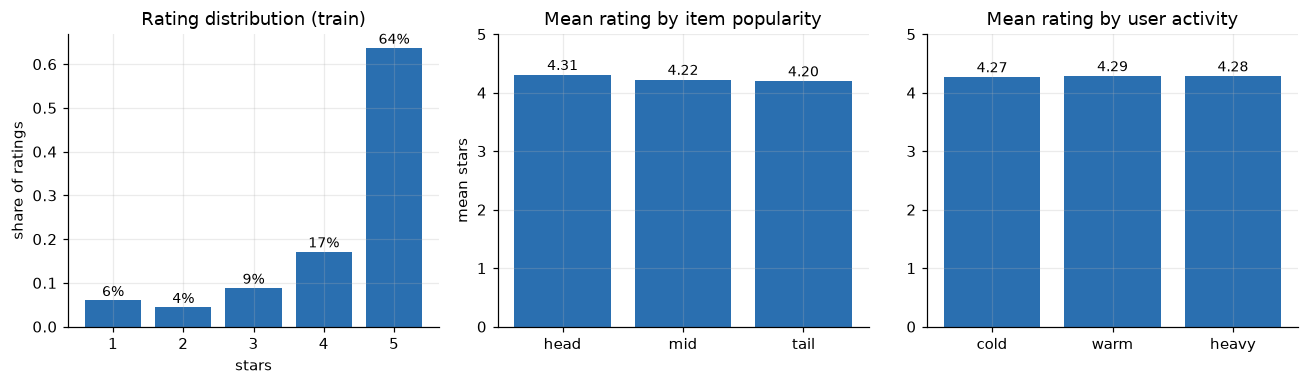

{'head': 4.307, 'mid': 4.225, 'tail': 4.2} {'cold': 4.269999980926514, 'warm': 4.2870001792907715, 'heavy': 4.283999919891357}
global mean rating: 4.281
rating std by split: train 1.167, val 1.226, test 1.292


In [35]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
share = train["rating"].value_counts(normalize=True).sort_index()
ax[0].bar(share.index, share.values, color=BLUE)
ax[0].set(title="Rating distribution (train)", xlabel="stars", ylabel="share of ratings")
for x, y in share.items():
    ax[0].text(x, y + 0.01, f"{y:.0%}", ha="center", fontsize=9)

by_item = items.groupby("pop_bin")["item_idx"].apply(lambda s: train[train.item_idx.isin(s)]["rating"].mean())
order = ["head", "mid", "tail"]
ax[1].bar(order, by_item.loc[order].values, color=BLUE)
ax[1].set(title="Mean rating by item popularity", ylabel="mean stars", ylim=(0, 5))
for x, y in zip(order, by_item.loc[order].values):
    ax[1].text(x, y + 0.08, f"{y:.2f}", ha="center", fontsize=9)

by_user = users.set_index("user_idx")["activity_bin"]
ub = train.assign(b=by_user.reindex(train.user_idx).to_numpy()).groupby("b")["rating"].mean().loc[["cold", "warm", "heavy"]]
ax[2].bar(ub.index, ub.values, color=BLUE)
ax[2].set(title="Mean rating by user activity", ylim=(0, 5))
for x, y in zip(ub.index, ub.values):
    ax[2].text(x, y + 0.08, f"{y:.2f}", ha="center", fontsize=9)
save("ratings")
print(by_item.loc[order].round(3).to_dict(), ub.round(3).to_dict())
print("global mean rating:", round(train.rating.mean(), 3))
print("rating std by split: train %.3f, val %.3f, test %.3f" % (train.rating.std(), val.rating.std(), test.rating.std()))

### 4.2 Interactions per user and per item

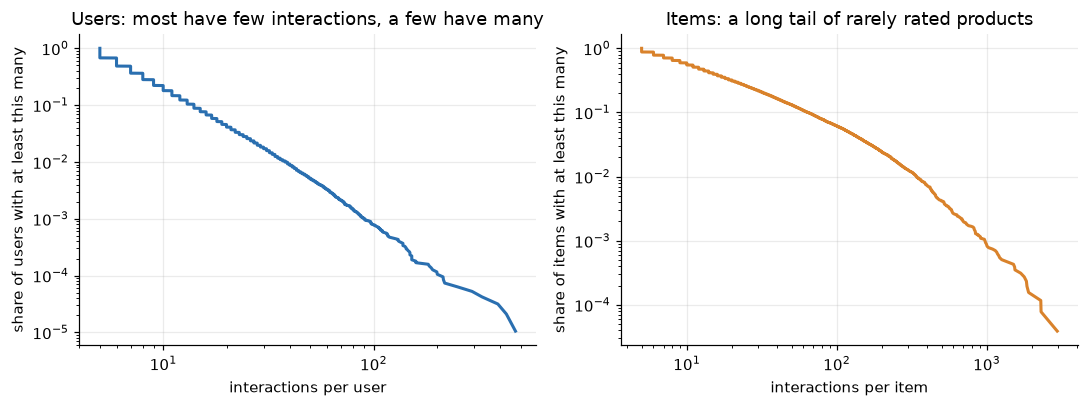

user: min 5, median 6, mean 8.6, 90th pct 14, 99th pct 38, max 473
item: min 5, median 12, mean 31.8, 90th pct 64, 99th pct 341, max 2955


In [36]:
per_user = allx.groupby("user_idx").size()
per_item = allx.groupby("item_idx").size()

def ccdf(ax, s, color, label):
    v = np.sort(s.to_numpy())
    ax.loglog(v, 1 - np.arange(len(v)) / len(v), color=color, lw=2)
    ax.set(xlabel=f"interactions per {label}", ylabel=f"share of {label}s with at least this many")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ccdf(ax[0], per_user, BLUE, "user"); ax[0].set_title("Users: most have few interactions, a few have many")
ccdf(ax[1], per_item, ORANGE, "item"); ax[1].set_title("Items: a long tail of rarely rated products")
save("degree_ccdf")
for name, s in (("user", per_user), ("item", per_item)):
    print(f"{name}: min {s.min()}, median {s.median():.0f}, mean {s.mean():.1f}, 90th pct {s.quantile(.9):.0f}, 99th pct {s.quantile(.99):.0f}, max {s.max()}")

### 4.3 Concentration: popular items and active users

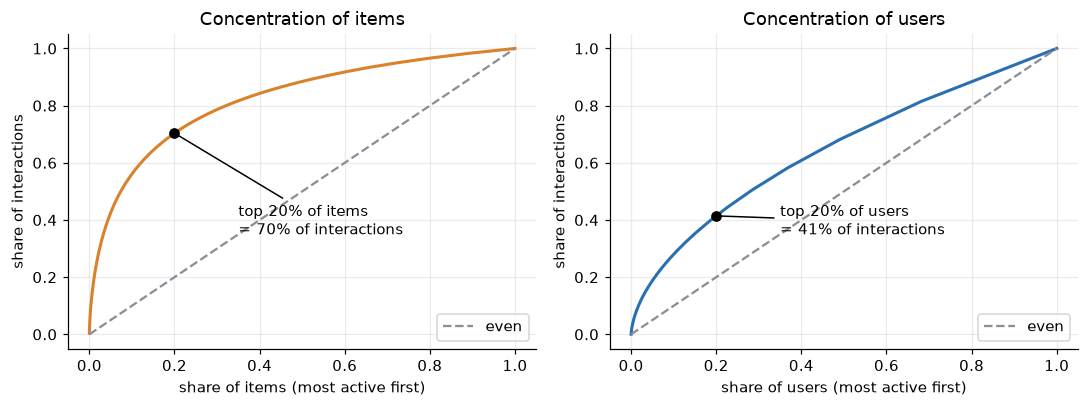

items: top 1% hold 18.6%, top 10% hold 56.1%, top 20% hold 70.4%
users: top 1% hold 7.1%, top 10% hold 28.0%, top 20% hold 41.4%


In [37]:
def lorenz(counts):
    v = np.sort(counts.to_numpy())[::-1]
    return np.arange(1, len(v) + 1) / len(v), np.cumsum(v) / v.sum()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, s, c, label in ((ax[0], per_item, ORANGE, "items"), (ax[1], per_user, BLUE, "users")):
    x, y = lorenz(s)
    a.plot(x, y, color=c, lw=2); a.plot([0, 1], [0, 1], color=GRAY, ls="--", label="even")
    i20 = int(0.2 * len(x)); a.scatter([x[i20]], [y[i20]], color="black", zorder=3)
    a.annotate(f"top 20% of {label}\n= {y[i20]:.0%} of interactions", (x[i20], y[i20]), (0.35, 0.35), arrowprops=dict(arrowstyle="-", color="black"))
    a.set(xlabel=f"share of {label} (most active first)", ylabel="share of interactions", title=f"Concentration of {label}")
    a.legend(loc="lower right")
save("concentration")
for name, s in (("items", per_item), ("users", per_user)):
    v = np.sort(s.to_numpy())[::-1]
    print(f"{name}: top 1% hold {v[:max(1, len(v)//100)].sum() / v.sum():.1%}, top 10% hold {v[:len(v)//10].sum() / v.sum():.1%}, top 20% hold {v[:len(v)//5].sum() / v.sum():.1%}")

In [38]:
top = items.sort_values("n_train", ascending=False).head(10)[["title", "store", "n_train", "item_idx"]].copy()
top["mean rating"] = train.groupby("item_idx")["rating"].mean().reindex(top["item_idx"]).round(2).to_numpy()
top["title"] = top["title"].str.slice(0, 70)
top.drop(columns="item_idx").rename(columns={"n_train": "train interactions"}).reset_index(drop=True)

,title,store,train interactions,mean rating
0,amFilm Tempered Glass Screen Protector for Nin...,amFilm,2062,4.68
1,Skyrim VR - PlayStation 4,Bethesda,1833,4.50
2,Grand Theft Auto V: Premium Edition - Xbox One...,Rockstar Games,1768,4.57
3,PlayStation 4 500GB Console [Old Model][Discon...,PlayStation,1559,4.40
4,Xbox Live Gold: 1 Month Membership [Digital Code],Xbox,1400,4.73
5,Assassin's Creed IV Black Flag - PC,Ubisoft,1298,4.57
6,Battlefield 4 - Playstation 3,Electronic Arts,1276,3.79
7,Fallout 4 - Xbox One,Bethesda,1275,4.33
8,PlayStation Plus: 12 Month Membership [Digital...,PlayStation,1272,4.77
9,DualShock 4 Wireless Controller for PlayStatio...,PlayStation,1175,4.53


### 4.4 The user-item interaction matrix

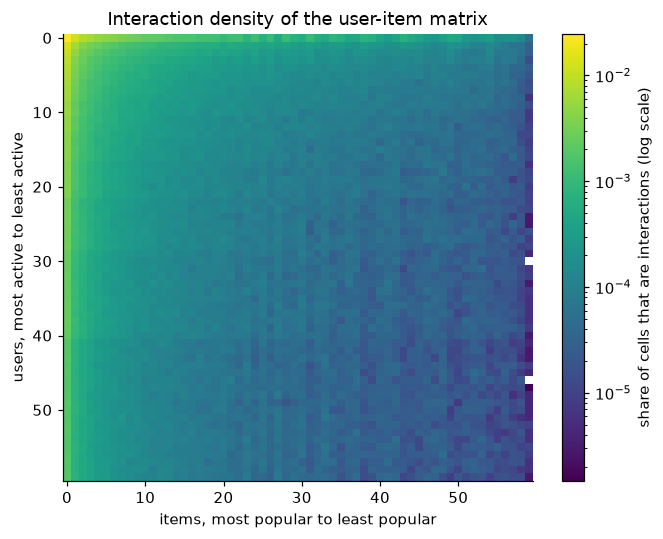

densest cell 2.457%, sparsest nonzero cell 0.00015%, overall 0.0258%


In [39]:
# Rank users and items by activity, cut each axis into 60 equal-count groups, and plot interaction density per cell.
u_rank = (-users["n_train"]).rank(method="first").to_numpy().astype(int) - 1
i_rank = (-items["n_train"]).rank(method="first").to_numpy().astype(int) - 1
nb = 60
ub_, ib_ = u_rank[train.user_idx] * nb // data.n_users, i_rank[train.item_idx] * nb // data.n_items
cell = np.zeros((nb, nb)); np.add.at(cell, (ub_, ib_), 1)
density = cell / ((data.n_users / nb) * (data.n_items / nb))

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(density, norm=LogNorm(vmin=density[density > 0].min(), vmax=density.max()), cmap="viridis", aspect="auto")
ax.set(xlabel="items, most popular to least popular", ylabel="users, most active to least active", title="Interaction density of the user-item matrix")
ax.grid(False); plt.colorbar(im, label="share of cells that are interactions (log scale)")
save("matrix_density")
print(f"densest cell {density.max():.3%}, sparsest nonzero cell {density[density > 0].min():.5%}, overall {len(train) / (data.n_users * data.n_items):.4%}")

White cells contain no interactions. Interactions pile up in the corner where active users meet popular items, and the least popular items are nearly empty.

### 4.5 Time

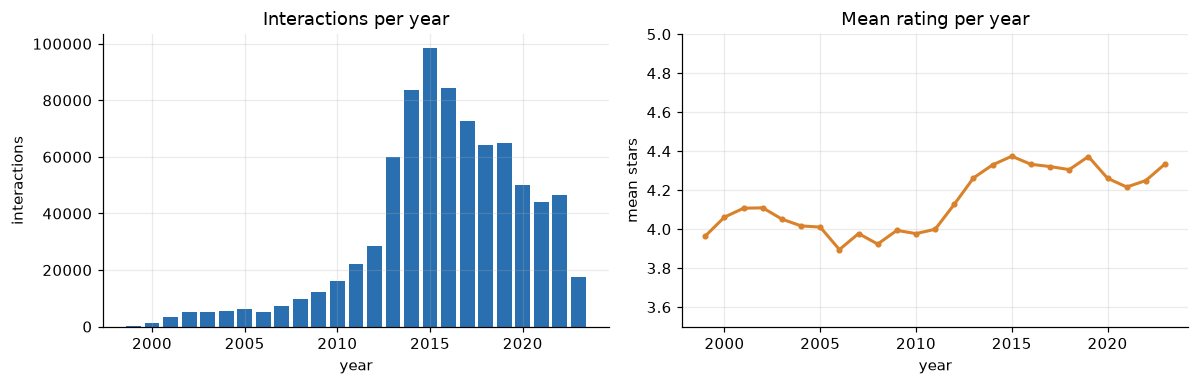

share of interactions from 2015 on: 0.666 | busiest year: 2015 (98,466)


In [40]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
yr = allx.groupby("year").size()
ax[0].bar(yr.index, yr.values, color=BLUE); ax[0].set(title="Interactions per year", xlabel="year", ylabel="interactions")
my = allx.groupby("year")["rating"].mean()
ax[1].plot(my.index, my.values, color=ORANGE, lw=2, marker="o", ms=3); ax[1].set(title="Mean rating per year", xlabel="year", ylabel="mean stars", ylim=(3.5, 5))
save("time")
print("share of interactions from 2015 on:", round((allx.year >= 2015).mean(), 3), "| busiest year:", yr.idxmax(), f"({yr.max():,})")

### 4.6 Item attributes

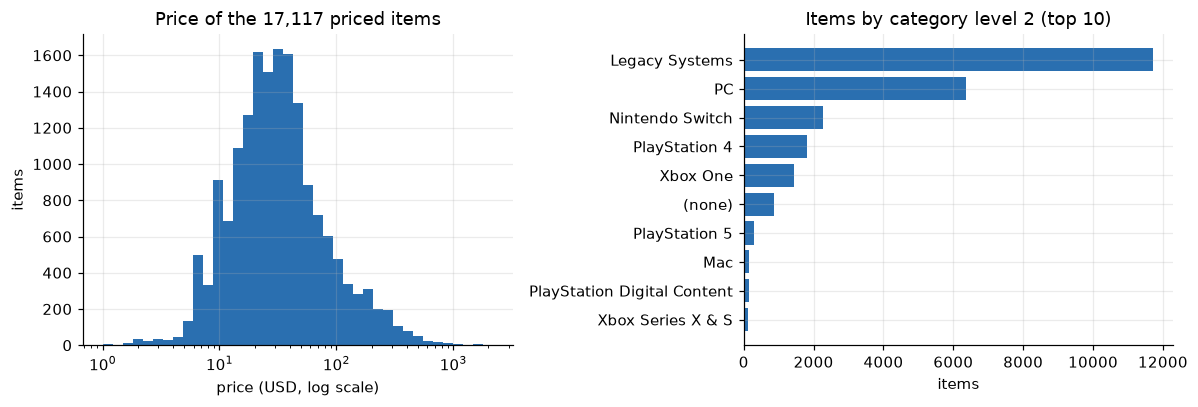

price median / p99 / max: 29.92 397.81 2189.75 | 14 items priced under $1 not plotted
price_log_z after scaling (priced items): mean 0.0 std 1.0


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
p = items["price"].dropna(); below_one = int((p < 1).sum()); p = p[p >= 1]
ax[0].hist(p, bins=np.logspace(np.log10(p.min()), np.log10(p.max()), 40), color=BLUE)
ax[0].set(xscale="log", title=f"Price of the {len(p):,} priced items", xlabel="price (USD, log scale)", ylabel="items")
cat2 = items["categories"].str.split(" > ").str[1].fillna("(none)").value_counts().head(10)[::-1]
ax[1].barh(cat2.index, cat2.values, color=BLUE); ax[1].set(title="Items by category level 2 (top 10)", xlabel="items")
save("attributes")
print("price median / p99 / max:", round(p.median(), 2), round(p.quantile(.99), 2), round(p.max(), 2), f"| {below_one} items priced under $1 not plotted")
print("price_log_z after scaling (priced items): mean", round(items.loc[items.price_missing == 0, "price_log_z"].mean(), 4),
      "std", round(items.loc[items.price_missing == 0, "price_log_z"].std(), 4))

### 4.7 Sequence length, cold items, and what the test set looks like

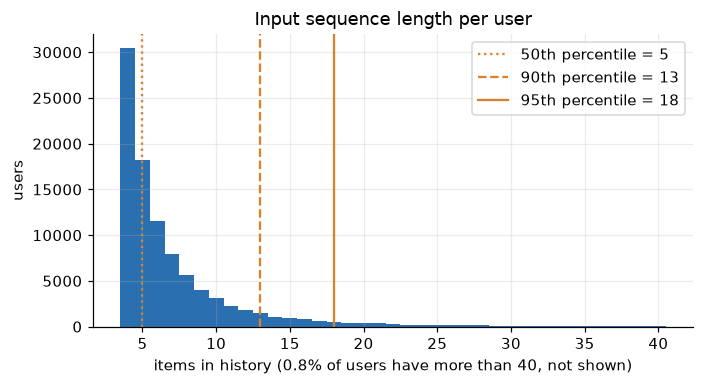

{0.5: 5.0, 0.9: 13.0, 0.95: 18.0, 0.99: 37.0} | max 472


In [42]:
seq = users["n_train"] + 1   # train items plus the validation item = what a sequence model sees at test time
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(seq[seq <= 40], bins=np.arange(3.5, 41.5), color=BLUE)
for q, ls in ((0.5, ":"), (0.9, "--"), (0.95, "-")):
    ax.axvline(seq.quantile(q), color=ORANGE, ls=ls, label=f"{int(q*100)}th percentile = {seq.quantile(q):.0f}")
ax.set(title="Input sequence length per user", xlabel=f"items in history ({(seq > 40).mean():.1%} of users have more than 40, not shown)", ylabel="users"); ax.legend()
save("sequence_length")
print({q: float(seq.quantile(q)) for q in (0.5, 0.9, 0.95, 0.99)}, "| max", int(seq.max()))

In [43]:
test_bin = items["pop_bin"].to_numpy()[test["item_idx"]]
tb = pd.Series(test_bin).value_counts(normalize=True).reindex(["head", "mid", "tail", "cold"])
print("test targets by popularity of the target item:"); print((tb * 100).round(2).astype(str).add("%").to_string())
print()
print("items per bin:", items["pop_bin"].value_counts().reindex(["head", "mid", "tail", "cold"]).to_dict())
print("test targets on items never seen in train:", int((test_bin == "cold").sum()))
print("users per activity bin:", users["activity_bin"].value_counts().to_dict(), "|", data.meta["user_activity_bins"])
pd.crosstab(users["activity_bin"], pd.Series(test_bin, index=users.index, name="target item bin")).loc[["cold", "warm", "heavy"], ["head", "mid", "tail", "cold"]]

test targets by popularity of the target item:
head    63.45%
mid     18.27%
tail    17.91%
cold     0.36%

items per bin: {'head': 5106, 'mid': 7658, 'tail': 12763, 'cold': 85}
test targets on items never seen in train: 345
users per activity bin: {'cold': 48624, 'heavy': 26671, 'warm': 19467} | {'cold': 'n_train <= 4', 'warm': '4 < n_train <= 6', 'heavy': 'n_train > 6'}


target item bin,head,mid,tail,cold
activity_bin,,,,
cold,31383,8725,8350,166
warm,12377,3564,3466,60
heavy,16366,5026,5160,119


## Findings of the exploratory analysis

**1. We model the dense core of Amazon, not the typical shopper.** The 5-core filter keeps 17.9% of interactions, 3.4% of users and 18.7% of items
(4.56M interactions down to 814,586). Results describe users with at least five reviews. The raw file had no malformed rows, missing fields or invalid
values, so cleaning removed only 69,115 repeated user-item pairs.

**2. Ratings carry little signal.** 64% of ratings are five stars (mean 4.28), and the mean barely moves with item popularity (4.31 head, 4.23 mid, 4.20 tail)
or user activity (4.27 to 4.29). Held-out ratings are also more spread out than training ratings (std 1.29 test, 1.23 validation, 1.17 train).
We therefore expect modest gains in rating prediction: predicting the global mean gives test RMSE 1.295 and a shrunk item mean gives 1.250. Ranking metrics are the more informative evaluation.

**3. Popularity dominates, so popularity is a hard baseline.** The top 20% of items hold 70.4% of interactions, and 63.5% of test targets are head items.
A recommender that shows everyone the same list already reaches Recall@10 = 0.0249 against 0.0004 for chance. Beating it requires real personalisation,
which is why we report results by item-popularity slice and add coverage, novelty and Gini.

**4. Activity is skewed but milder than popularity.** The top 10% of users hold 28.0% of interactions. The median user has 6 interactions in total and the maximum is 473
(most active item: 2,955). The matrix is extremely sparse (density 0.034%), with interactions packed where active users meet popular items.

**5. Histories are short.** At test time the median user has 5 items of history, 95% have 18 or fewer and 99% have 37 or fewer. A sequential model only needs a
maximum length of about 20, and it has little context to exploit for most users, so a large advantage over simpler models should not be assumed.

**6. Cold start is small but real.** 85 items (0.3%) have no training interactions and 345 test targets (0.36%) fall on them, while 17.9% of test targets are tail items.
Collaborative models cannot rank cold items. This is where a text-based model can help.

**7. The catalog is broader than games.** 30% of items have a main category other than Video Games (Computers 3,263, All Electronics 2,645, Cell Phones 414, ...), and the most
interacted item is a Nintendo Switch screen protector, alongside Xbox Live and PlayStation Plus memberships and consoles. Items like these may strengthen
the popularity signal.

**8. Time and metadata.** 67% of interactions are from 2015 onward (peak 2015, 98,466) and mean rating rose from about 4.0 in the 2000s to about 4.3. Because the split is per user,
test interactions span 1999 to 2023 rather than one cut-off date. Item metadata is incomplete: price is missing for 33.1% of items, the description is empty for 26.6% and features for 12.9%,
so the text field falls back to whichever parts exist and price carries a missing flag.

# Part 2. The evaluation protocol

Every model is scored by the same code (`recsys.metrics`, `recsys.harness`), which is what makes the comparison fair.
- **Split:** per user, leave-one-out by time. The last interaction is the test item, the second-to-last the validation item, the rest is training.
- **Ranking:** each model scores **all 25,612 items** for each user (no sampled negatives); items the user already has are removed; we record the rank of the held-out item. Full ranking is deliberate: sampled-negative evaluation is known to distort model rankings (Krichene and Rendle, 2020), so the proposal commits to ranking the whole catalog.
- **Ties:** rank = 1 + the number of other items scoring at least as high as the target, so a model that returns equal scores for everything gets the worst possible rank.
- **Metrics:** Precision, Recall, F1 and NDCG at k = 5, 10 and 20, MRR, and RMSE/MAE for the rating model. With one relevant item, recall@k is the hit rate and precision and F1 are functions of it, so Recall@10, NDCG@10 and MRR are the headline numbers.
- **Beyond accuracy:** catalog coverage, novelty, average popularity of recommended items and the Gini index of item exposure; **cost:** training time, scoring time per user, parameter count.
- **Selection:** every hyperparameter is chosen on the validation split only (NDCG@10; lowest RMSE for the rating model). The test split is never used inside any model.

In [44]:
from recsys.metrics import ranking_metrics, target_ranks
print("three users whose held-out item ranked 1st, 3rd and 11th:")
print({k: round(v, 4) for k, v in ranking_metrics(np.array([1, 3, 11]), ks=(10,)).items()})
print("a model that scores every item the same gets the worst rank, not a lucky one:",
      int(target_ranks(np.zeros((1, 5), dtype=np.float32), np.array([2]))[0]), "out of 5")

three users whose held-out item ranked 1st, 3rd and 11th:
{'precision@10': 0.0667, 'recall@10': 0.6667, 'f1@10': 0.1212, 'ndcg@10': 0.5, 'mrr': 0.4747}
a model that scores every item the same gets the worst rank, not a lucky one: 5 out of 5


# Part 3. Models, hyperparameter sweeps and training curves

Each section gives the idea, the validation-chosen sweep (all runs read from `results/`, the winner marked) and the training curve of the final run. The code of every model is in Part 0.

In [45]:
from recsys.report import sweep_table

def curve_plot(model):
    r = json.load(open(RESULTS_DIR / f"{model}_final.json"))
    if not r.get("curve"):
        print(f"{model} has no iterative training curve")
        return
    c = pd.DataFrame(r["curve"])
    xcol = "epoch" if "epoch" in c else "iteration"
    ycols = [k for k in c.columns if k != xcol]
    fig, axes = plt.subplots(1, len(ycols), figsize=(4.6 * len(ycols), 3.4))
    for ax, y in zip(np.atleast_1d(axes), ycols):
        ax.plot(c[xcol], c[y], color=BLUE, lw=2, marker="o", ms=3)
        if r.get("best_epoch"):
            ax.axvline(r["best_epoch"], color=ORANGE, ls="--", label=f"best epoch {r['best_epoch']}")
            ax.legend(frameon=False)
        ax.set(xlabel=xcol, ylabel=y, title=f"{model}: {y}")
    plt.tight_layout(); plt.savefig(FIG / f"curve_{model}.png", dpi=150); plt.show()

## popularity
Recommends the items with the most training interactions to everybody. No personalisation: the baseline every other model has to beat. For rating prediction it uses a shrunk item mean, (sum of item ratings + m * global mean) / (count + m) with m = 10 chosen on validation.

In [46]:
sw = sweep_table("popularity")
print("popularity: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "val_rmse", "test_recall@10", "fit_seconds", "selected"]].head(12)

popularity: 1 runs, winner on validation: popularity_final


,run,cfg_shrinkage,val_ndcg@10,val_rmse,test_recall@10,fit_seconds,selected
0,popularity_final,10,0.013568,1.17948,0.024915,0.0,True


Everyone gets the same list, the most-interacted items. Test Recall@10 is 0.0249, about 64 times chance (0.0004), and NDCG@10 is 0.0126. For ratings, the shrunk item mean (m = 10, chosen on validation) gives test RMSE 1.2500 against 1.2949 for predicting the global mean.

## knn
Item-item collaborative filtering. Two items are similar if the same users interacted with both (cosine similarity on the implicit matrix); a user's score for an item is its summed similarity to the items in their history. Only the top k neighbours per item are stored.

In [47]:
sw = sweep_table("knn")
print("knn: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

knn: 9 runs, winner on validation: knn_final


,run,cfg_k,val_ndcg@10,test_recall@10,fit_seconds,selected
0,knn_final,3200,0.037851,0.056246,0.32,True
1,knn_k3200,3200,0.037851,0.056246,0.30,True
2,knn_k1600,1600,0.037737,0.056098,0.30,False
3,knn_k800,800,0.037365,0.055349,0.28,False
4,knn_k400,400,0.036632,0.053977,0.26,False
5,knn_k200,200,0.035829,0.052437,0.24,False
6,knn_k100,100,0.035077,0.050326,0.22,False
7,knn_k50,50,0.034124,0.048965,0.22,False
8,knn_k20,20,0.032987,0.047656,0.19,False


Validation NDCG@10 rises with the number of neighbours kept per item, from 0.0330 at k = 20 to 0.0379 at k = 3200, and is flat from k = 1600 (0.0377), so the winner is not far from the plateau. The final run has test Recall@10 0.0562 and NDCG@10 0.0312, fits in 0.3 s and scores a user in 0.048 ms. It stores 7.1 million similarities.

## als
Implicit-feedback matrix factorization (Hu, Koren and Volinsky, 2008). Every user and item gets a short vector fitted by alternating closed-form least squares, with confidence 1 + alpha on observed interactions. It cannot score users it never saw in training; the optional fold-in computes a vector from their revealed purchases.

In [48]:
sw = sweep_table("als")
print("als: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

als: 13 runs, winner on validation: als_factors256


,run,cfg_factors,cfg_reg,cfg_alpha,cfg_iterations,cfg_foldin,cfg_foldin_all,val_ndcg@10,test_recall@10,fit_seconds,selected
0,als_factors256,256,0.10,40.0,15,False,NaN,0.052444,0.059771,931.65,True
1,als_final,256,0.10,40.0,15,False,False,0.052444,0.059771,795.93,True
2,als_f128_r0.01,128,0.01,40.0,15,False,NaN,0.049420,0.059285,134.07,False
3,als_f128,128,0.10,40.0,15,False,NaN,0.049417,0.059285,134.49,False
4,als_factors128_reg10,128,10.00,40.0,15,False,NaN,0.049403,0.059454,130.99,False
5,als_f128_r1.0,128,1.00,40.0,15,False,NaN,0.049394,0.059338,134.52,False
6,als_f128_a100,128,0.10,100.0,15,False,NaN,0.049288,0.058916,132.60,False
7,als_factors128_reg100,128,100.00,40.0,15,False,NaN,0.048869,0.059222,128.49,False
8,als_f128_a10,128,0.10,10.0,15,False,NaN,0.045839,0.056542,133.29,False
9,als,64,0.10,40.0,15,False,NaN,0.044937,0.057354,44.88,False


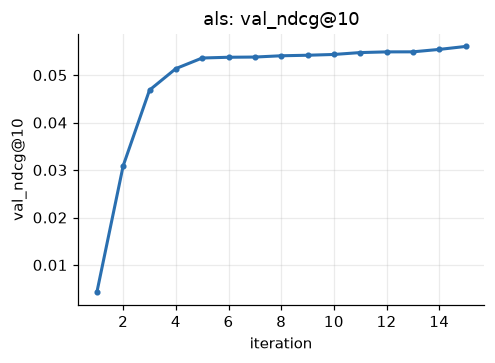

In [49]:
curve_plot("als")

In [50]:
rows = []
for run, label in (("als_final", "als: learned user vectors"), ("als_foldall", "als+history: user vectors computed from the history given")):
    r = json.load(open(RESULTS_DIR / f"{run}.json"))
    rows.append({"variant": label, "val_ndcg@10": r["val"]["ndcg@10"], "test_recall@10": r["test"]["recall@10"],
                 "test_ndcg@10": r["test"]["ndcg@10"], "test_mrr": r["test"]["mrr"]})
pd.DataFrame(rows).round(4)

,variant,val_ndcg@10,test_recall@10,test_ndcg@10,test_mrr
0,als: learned user vectors,0.0524,0.0598,0.0324,0.0292
1,als+history: user vectors computed from the hi...,0.0525,0.0785,0.0432,0.0385


Validation NDCG@10 by number of factors: 0.0400 at 32, 0.0449 at 64, 0.0494 at 128, 0.0524 at 256; fit times 16 s, 45 s, 134 s, 796 s. Doubling the factors costs about 5.9 times the training time for a smaller gain each time. Regularisation between 0.01 and 100 barely matters (validation NDCG@10 within 0.0006) and 1000 hurts (0.0210); confidence alpha = 10 is worse (0.0458) and 100 is no better than 40 (0.0493). The final run (256 factors) has test Recall@10 0.0598 and NDCG@10 0.0324. Its validation NDCG@10 (0.0524) is far above its test NDCG@10 because the learned user vectors never saw the validation purchase, which the test item is scored after. Computing each user's vector from the history the harness gives it (the same item factors, nothing retrained; the row called als+history) raises test NDCG@10 from 0.0324 to 0.0432 and Recall@10 from 0.0598 to 0.0785, closing 54% of the validation-to-test gap, so a large part of that gap is the evaluation protocol and not the model. This variant was added after noticing the gap, it has no tunable parameters, and it is reported next to plain ALS, not instead of it.

## svd
Biased matrix factorization for rating prediction: mu + user bias + item bias + user vector . item vector, trained with Adam on squared error. It is the model for the RMSE metric; for the ranking metrics it ranks items by predicted rating.

In [51]:
sw = sweep_table("svd", by='val_rmse')
print("svd: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "val_rmse", "test_recall@10", "fit_seconds", "selected"]].head(12)

svd: 24 runs, winner on validation: svd_final


,run,cfg_factors,cfg_lr,cfg_reg,cfg_epochs,cfg_patience,cfg_batch_size,val_ndcg@10,val_rmse,test_recall@10,fit_seconds,selected
0,svd_final,32,0.005,0.5,30,3,8192,0.000059,1.096752,0.000306,15.93,True
1,svd_factors32_reg0.5,32,0.005,0.5,30,3,8192,0.000059,1.096752,0.000306,17.68,False
2,svd_factors16_reg0.5,16,0.005,0.5,30,3,8192,0.000048,1.096959,0.000285,12.51,False
3,svd_factors64_reg0.5,64,0.005,0.5,30,3,8192,0.000059,1.096982,0.000232,23.85,False
4,svd_factors8_reg0.5,8,0.005,0.5,30,3,8192,0.000040,1.097001,0.000306,11.47,False
5,svd_factors64_reg0.2,64,0.005,0.2,30,3,8192,0.000132,1.102036,0.000306,26.56,False
6,svd_factors32_reg1.0,32,0.005,1.0,30,3,8192,0.000073,1.105356,0.000317,15.45,False
7,svd_factors16_reg1.0,16,0.005,1.0,30,3,8192,0.000073,1.105356,0.000317,11.65,False
8,svd_factors32_reg0.2,32,0.005,0.2,30,3,8192,0.000087,1.109012,0.000232,18.28,False
9,svd_factors64_reg0.1,64,0.005,0.1,30,3,8192,0.000200,1.113677,0.000317,23.60,False


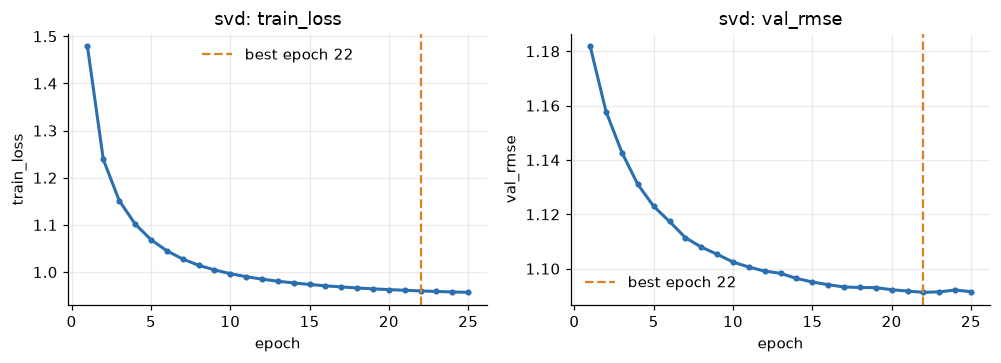

In [52]:
curve_plot("svd")

Validation RMSE falls from 1.1538 at reg 0.05 to 1.0968 at reg 0.5 and rises again beyond it; the number of factors hardly matters at that regularisation. Final test RMSE is 1.1785 (MAE 0.8334) against 1.2500 for the popularity baseline, an improvement of 5.7%. As a recommender it is no better than chance: Recall@10 is 0.0003 against 0.0004 for chance. Predicting a rating accurately and ranking the items a user will buy are different problems, and a model trained on rating error does not solve the second.

## bpr
Bayesian personalised ranking matrix factorization (Rendle et al., 2009). Trained directly to rank: an item the user interacted with should score above a sampled item they did not.

In [53]:
sw = sweep_table("bpr")
print("bpr: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

bpr: 17 runs, winner on validation: bpr_final

,run,cfg_factors,cfg_lr,cfg_reg,cfg_epochs,cfg_batch_size,cfg_patience,val_ndcg@10,test_recall@10,fit_seconds,selected
0,bpr_final,128,0.005,0.003,80,4096,15,0.039843,0.051951,174.30,True
1,bpr_patience15_epochs80_factors128_reg0.003,128,0.005,0.003,80,4096,15,0.039843,0.051951,168.87,True
2,bpr_r2_f128_reg0.001,128,0.005,0.001,150,4096,30,0.039786,0.051529,564.69,False
3,bpr_r2_f256,256,0.005,0.003,150,4096,15,0.037887,0.049102,265.90,False
4,bpr_patience15_epochs80_factors64_reg0.003,64,0.005,0.003,80,4096,15,0.035743,0.047625,112.54,False
5,bpr_patience15_epochs80_factors64_reg0.01,64,0.005,0.010,80,4096,15,0.033408,0.047065,94.54,False
6,bpr_patience15_epochs80_factors128_reg0.01,128,0.005,0.010,80,4096,15,0.033097,0.047435,70.38,False
7,bpr_factors64_reg0.003,64,0.005,0.003,50,4096,5,0.030940,0.042179,74.12,False
8,bpr_factors64_reg0.01,64,0.005,0.010,50,4096,5,0.030464,0.043256,38.45,False
9,bpr_r2_f128_lr0.01,128,0.010,0.003,150,4096,15,0.028904,0.040406,150.01,False


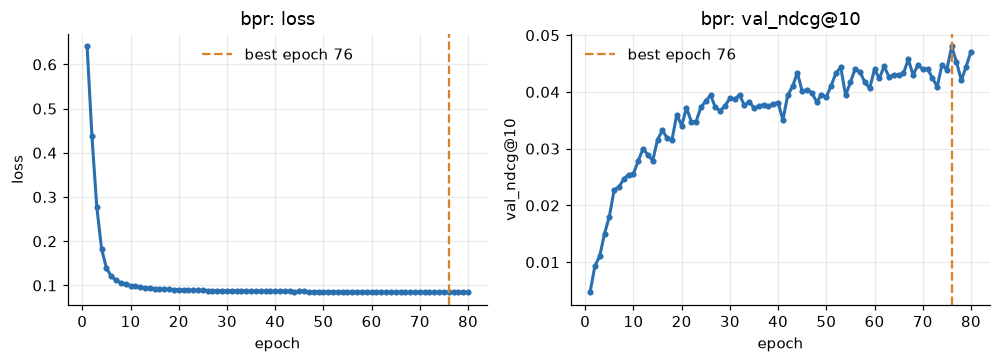

In [54]:
curve_plot("bpr")

BPR is sensitive to regularisation. With reg of 0.001 or less, training stopped at the popularity solution (validation NDCG@10 0.0169 against popularity's 0.0136); reg 0.003 to 0.01 learned real preferences (0.0309 and 0.0305); longer patience and 128 factors raised it to 0.0398. The final run has test Recall@10 0.0520 and NDCG@10 0.0271 after 76 of 80 epochs, fitting in 174 s. Its best epoch is at the 80-epoch cap, so it was still improving; a 150-epoch run with weaker regularisation reached the same validation score (0.0398), so BPR looks close to its ceiling on this data but may be slightly undertrained.

## ncf
Neural collaborative filtering, NeuMF (He et al., 2017). A GMF tower (elementwise product of embeddings) and an MLP tower (concatenated embeddings through hidden layers) are joined by one linear layer. Trained with sampled negatives and binary cross-entropy.

In [55]:
sw = sweep_table("ncf")
print("ncf: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

ncf: 12 runs, winner on validation: ncf_final


,run,cfg_factors,cfg_mlp_factors,cfg_layers,cfg_lr,cfg_neg,cfg_batch_size,cfg_epochs,cfg_patience,cfg_reg,cfg_dropout,val_ndcg@10,test_recall@10,fit_seconds,selected
0,ncf_final,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0030,0.2,0.024887,0.037705,65.78,True
1,ncf_dropout0.2_patience5_epochs40_reg0.003,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0030,0.2,0.024865,0.037599,134.10,False
2,ncf_dropout0.2_patience5_epochs40_reg0.005,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0050,0.2,0.024678,0.037483,83.21,False
3,ncf_reg0.003_patience5_epochs40_dropout0.5,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0030,0.5,0.024311,0.035331,125.25,False
4,ncf_reg0.001_patience5_epochs40_dropout0.5,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0010,0.5,0.022638,0.032144,143.09,False
5,ncf_dropout0.2_patience5_epochs40_reg0.001,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0010,0.2,0.022080,0.031204,212.16,False
6,ncf_dropout0.2_patience5_epochs40_reg0.0003,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0003,0.2,0.019479,0.027690,199.61,False
7,ncf_reg0.003_dropout0.2_patience5_epochs40_lr0...,32,32,"[64, 32, 16]",0.003,4,4096,40,5,0.0030,0.2,0.018886,0.029273,95.80,False
8,ncf_dropout0.2_patience5_epochs40_reg0.01,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0100,0.2,0.018376,0.031278,189.95,False
9,ncf_mlp_factors16_reg0.001_dropout0.2_patience...,16,16,"[64, 32, 16]",0.001,4,4096,40,5,0.0010,0.2,0.017070,0.026076,75.58,False


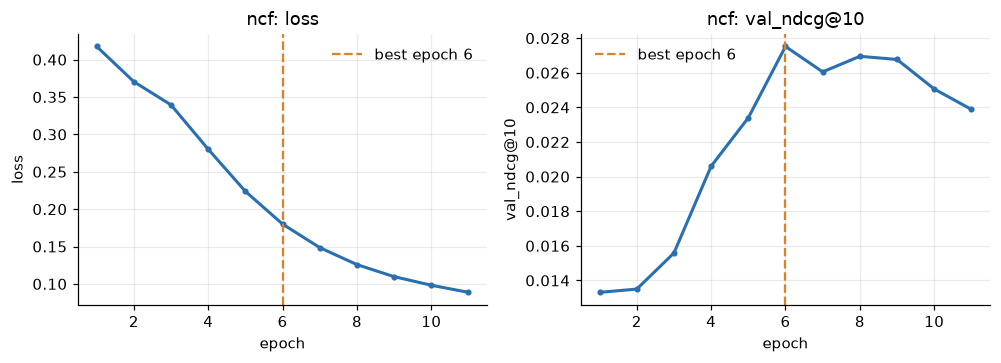

In [56]:
curve_plot("ncf")

The unregularised network memorises the training data: over 10 epochs its training loss fell from 0.41 to 0.06 while validation NDCG@10 stayed near 0.0169 and test Recall@10 was only 0.0250. An L2 penalty on the embeddings and dropout in the MLP helped substantially, though it stays well below the matrix-factorization models: the best setting (reg 0.003, dropout 0.2) reaches test Recall@10 0.0377 and NDCG@10 0.0197. Scoring all items takes 0.62 ms per user, about 13 times KNN, because every user-item pair goes through the MLP; the network has 7.7 million parameters.

## sasrec
Self-attentive sequential recommendation (Kang and McAuley, 2018): a transformer over the user's chronological purchases that predicts the next item. It scores users from the history it is given, so it handles new users with a few revealed purchases.

In [57]:
sw = sweep_table("sasrec")
print("sasrec: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

sasrec: 19 runs, winner on validation: sasrec_blocks1_dropout0.5_hidden128


,run,cfg_max_len,cfg_hidden,cfg_blocks,cfg_heads,cfg_dropout,cfg_lr,cfg_batch_size,cfg_epochs,cfg_patience,val_ndcg@10,test_recall@10,fit_seconds,selected
0,sasrec_blocks1_dropout0.5_hidden128,20,128,1,2,0.5,0.0010,256,50,5,0.037131,0.061807,107.77,True
1,sasrec_final,20,128,1,2,0.5,0.0010,256,50,5,0.036574,0.063211,99.49,False
2,sasrec_blocks1_dropout0.5_max_len30,30,64,1,2,0.5,0.0010,256,50,5,0.036483,0.061871,111.06,False
3,sasrec_blocks1_dropout0.5,20,64,1,2,0.5,0.0010,256,50,5,0.035710,0.060752,208.56,False
4,sasrec_blocks1_dropout0.6,20,64,1,2,0.6,0.0010,256,50,5,0.035623,0.061902,187.14,False
5,sasrec_blocks1_dropout0.4,20,64,1,2,0.4,0.0010,256,50,5,0.035348,0.062124,135.52,False
6,sasrec_blocks1_dropout0.5_max_len50,50,64,1,2,0.5,0.0010,256,50,5,0.034458,0.060573,116.96,False
7,sasrec_dropout0.4,20,64,2,2,0.4,0.0010,256,50,5,0.034092,0.058473,170.73,False
8,sasrec_blocks1_dropout0.5_hidden32,20,32,1,2,0.5,0.0010,256,50,5,0.032999,0.058051,89.29,False
9,sasrec_blocks1,20,64,1,2,0.2,0.0010,256,50,5,0.032719,0.056457,224.51,False


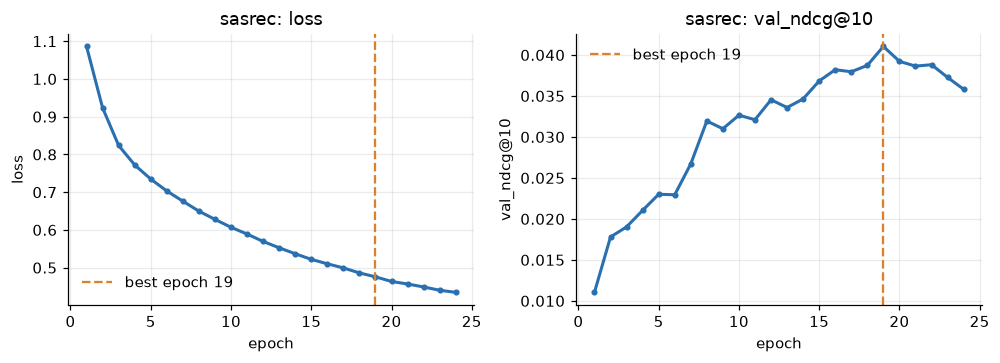

In [58]:
curve_plot("sasrec")

On this small dataset fewer blocks were better at equal dropout 0.2 (validation NDCG@10 0.0327 with one block, 0.0320 with two, 0.0284 with three) and more dropout helped (two blocks: 0.0297 with dropout 0.1, 0.0320 with 0.2, 0.0341 with 0.4). The final model (one block, hidden size 128, dropout 0.5, last 20 purchases) has test Recall@10 0.0632 and NDCG@10 0.0335. Its validation and test NDCG@10 (0.0366 and 0.0335) are close, consistent with it reading the history it is given, which at test time includes the validation purchase. Fit 99 s, scoring 0.016 ms per user, 3.4 million parameters.

## content
Content-based hybrid. Every item's text (title, features, description) is embedded with a frozen sentence-transformers encoder (all-MiniLM-L6-v2); a user's profile is the mean embedding of their history, plus a mild popularity prior. It can recommend items nobody has bought yet.

In [59]:
sw = sweep_table("content")
print("content: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

content: 13 runs, winner on validation: content_final


,run,cfg_lam,val_ndcg@10,test_recall@10,fit_seconds,selected
0,content_final,0.50,0.022477,0.038212,0.01,True
1,content_lam0.5,0.50,0.022477,0.038212,0.01,True
2,content_lam0.7,0.70,0.022390,0.038697,0.01,False
3,content_lam1.0,1.00,0.021271,0.037230,0.01,False
4,content_lam0.3,0.30,0.020825,0.035246,0.00,False
5,content_lam1.4,1.40,0.019558,0.034465,0.00,False
6,content_lam2,2.00,0.017642,0.031563,0.00,False
7,content_lam3,3.00,0.016380,0.028957,0.00,False
8,content_lam5,5.00,0.015651,0.027363,0.00,False
9,content_first,0.10,0.015144,0.025189,136.32,False


Text similarity alone (lam = 0) reaches test Recall@10 0.0183, 73% of popularity's, with no interaction data about the items. Adding a popularity prior helps up to lam = 0.5 (validation NDCG@10 0.0225); beyond that the model drifts back toward plain popularity. The final run has test Recall@10 0.0382 and NDCG@10 0.0199. The encoder is frozen, so nothing is trained and the run takes 0.01 s once the embeddings are cached.

## Final settings, and optional retraining

In [60]:
FINAL_CONFIGS = {'popularity': {'shrinkage': 10},
 'knn': {'k': 3200},
 'als': {'factors': 256, 'reg': 0.1, 'alpha': 40, 'iterations': 15, 'foldin': False, 'foldin_all': False},
 'svd': {'factors': 32, 'lr': 0.005, 'reg': 0.5, 'epochs': 30, 'patience': 3, 'batch_size': 8192},
 'bpr': {'factors': 128, 'lr': 0.005, 'reg': 0.003, 'epochs': 80, 'batch_size': 4096, 'patience': 15},
 'ncf': {'factors': 32,
         'mlp_factors': 32,
         'layers': [64, 32, 16],
         'lr': 0.001,
         'neg': 4,
         'batch_size': 4096,
         'epochs': 40,
         'patience': 5,
         'reg': 0.003,
         'dropout': 0.2},
 'sasrec': {'max_len': 20,
            'hidden': 128,
            'blocks': 1,
            'heads': 2,
            'dropout': 0.5,
            'lr': 0.001,
            'batch_size': 256,
            'epochs': 50,
            'patience': 5},
 'content': {'lam': 0.5}}

def run_final(name, cfg, data_obj, results_dir):
    import importlib
    import recsys.harness as harness
    from recsys.harness import run_experiment
    from recsys.models.base import Recommender
    module = importlib.import_module(f"recsys.models.{name}")
    cls = next(c for _, c in vars(module).items() if isinstance(c, type) and issubclass(c, Recommender) and c is not Recommender and c.__module__ == module.__name__)
    harness.RESULTS_DIR = results_dir
    model = cls(**cfg)
    run_experiment(model, data_obj, tag="final")
    return model

if RETRAIN:   # refit every final model on the full data and on the cold-start data (writes results/*_final.json)
    import recsys.harness as harness
    from recsys.harness import run_experiment
    cold_data = load(Path("data") / "processed_coldstart")
    for name, cfg in FINAL_CONFIGS.items():
        t0 = time.perf_counter()
        model = run_final(name, cfg, data, RESULTS_DIR)
        if name == "als":     # the same fitted ALS, every user scored from the history given (no retraining)
            model.foldin_all = True; model.config["foldin_all"] = True
            run_experiment(model, data, tag="foldall", fit=False)
        model = run_final(name, cfg, cold_data, RESULTS_DIR / "processed_coldstart")
        if name == "als":     # fold the revealed purchases of new users into the fitted ALS
            model.foldin = True; model.config["foldin"] = True
            run_experiment(model, cold_data, tag="foldin", fit=False)
        print(name, "done in", round(time.perf_counter() - t0), "s")
    harness.RESULTS_DIR = RESULTS_DIR
else:
    print("RETRAIN = False: the tables and charts below read the saved final runs for", sorted(FINAL_CONFIGS))

RETRAIN = False: the tables and charts below read the saved final runs for ['als', 'bpr', 'content', 'knn', 'ncf', 'popularity', 'sasrec', 'svd']


# Part 4. Results

Ranked by test NDCG@10: als+history 0.0432 > sasrec 0.0335 > als 0.0324 > knn 0.0312 > bpr 0.0271 > content 0.0199 > ncf 0.0197 > popularity 0.0126 > svd 0.0002. als+history is first with Recall@10 0.0785 [0.0768, 0.0802] and MRR 0.0385 [0.0376, 0.0395], 3.1 times the popularity baseline (0.0249 [0.0240, 0.0259]) and 201 times chance. Brackets are 95% bootstrap intervals over users; they measure uncertainty from the sample of users, not from training randomness (each model was trained once).

In [61]:
from recsys.analysis import comparison_table, paired_p_values, cost_table
from recsys.plots import comparison_chart, cost_scatter, tradeoff_scatter

table = comparison_table(RESULTS_DIR, metrics=("recall@10", "ndcg@10", "mrr"), n_boot=2000)
shown = table.copy()
for m in ("recall@10", "ndcg@10", "mrr"):
    shown[m] = [f"{v:.4f} [{lo:.4f}, {hi:.4f}]" for v, lo, hi in zip(table[m], table[f"{m}_lo"], table[f"{m}_hi"])]
shown[["model", "recall@10", "ndcg@10", "mrr"]]

,model,recall@10,ndcg@10,mrr
0,als+history,"0.0785 [0.0768, 0.0802]","0.0432 [0.0421, 0.0443]","0.0385 [0.0376, 0.0395]"
1,sasrec,"0.0632 [0.0616, 0.0648]","0.0335 [0.0326, 0.0345]","0.0311 [0.0303, 0.0319]"
2,als,"0.0598 [0.0583, 0.0612]","0.0324 [0.0315, 0.0333]","0.0292 [0.0284, 0.0300]"
3,knn,"0.0562 [0.0547, 0.0578]","0.0312 [0.0302, 0.0321]","0.0284 [0.0276, 0.0292]"
4,bpr,"0.0520 [0.0506, 0.0534]","0.0271 [0.0263, 0.0279]","0.0252 [0.0245, 0.0259]"
5,content,"0.0382 [0.0370, 0.0394]","0.0199 [0.0192, 0.0206]","0.0188 [0.0182, 0.0194]"
6,ncf,"0.0377 [0.0365, 0.0390]","0.0197 [0.0190, 0.0205]","0.0187 [0.0181, 0.0194]"
7,popularity,"0.0249 [0.0240, 0.0259]","0.0126 [0.0120, 0.0131]","0.0120 [0.0115, 0.0125]"
8,svd,"0.0003 [0.0002, 0.0004]","0.0002 [0.0001, 0.0002]","0.0003 [0.0003, 0.0004]"


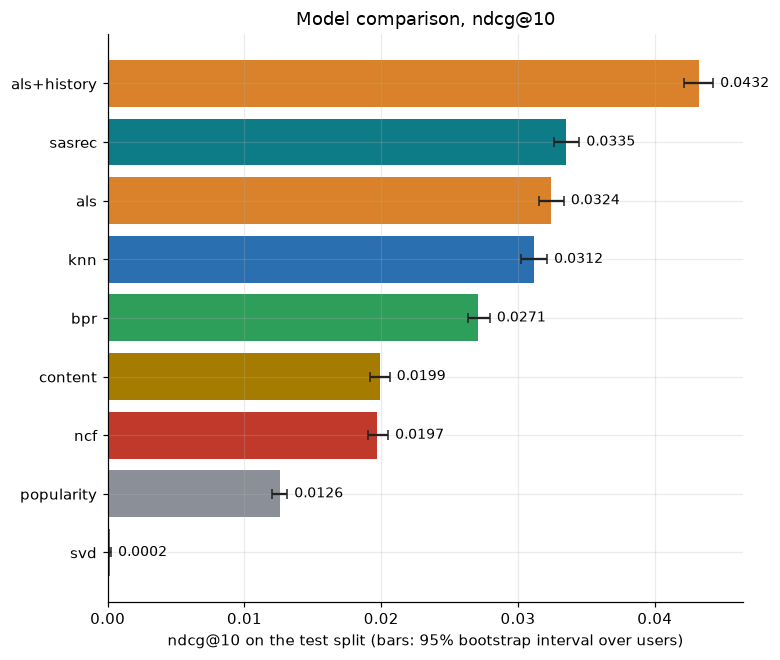

In [62]:
ax = comparison_chart(table, "ndcg@10"); ax.figure.tight_layout(); ax.figure.savefig(FIG / "results_ndcg.png", dpi=150); plt.show()

**Is one model really better than another?** Paired bootstrap over users (the same resampled users for every model). Below: NDCG@10 difference (row minus column) and the two-sided p-value.

In [63]:
diff, pval = paired_p_values(RESULTS_DIR, "ndcg@10", n_boot=2000)
print("difference in NDCG@10, row minus column"); display(diff.round(4))
print("two-sided bootstrap p-value (0.0000 means no resample reversed the order)"); display(pval.round(4))

difference in NDCG@10, row minus column


,als+history,sasrec,als,knn,bpr,content,ncf,popularity,svd
als+history,0.0000,0.0097,0.0108,0.0121,0.0161,0.0233,0.0235,0.0306,0.0430
sasrec,-0.0097,0.0000,0.0011,0.0024,0.0064,0.0136,0.0138,0.0210,0.0334
als,-0.0108,-0.0011,0.0000,0.0013,0.0053,0.0125,0.0127,0.0199,0.0323
knn,-0.0121,-0.0024,-0.0013,0.0000,0.0041,0.0113,0.0114,0.0186,0.0310
bpr,-0.0161,-0.0064,-0.0053,-0.0041,0.0000,0.0072,0.0074,0.0145,0.0269
content,-0.0233,-0.0136,-0.0125,-0.0113,-0.0072,0.0000,0.0002,0.0073,0.0197
ncf,-0.0235,-0.0138,-0.0127,-0.0114,-0.0074,-0.0002,0.0000,0.0072,0.0196
popularity,-0.0306,-0.0210,-0.0199,-0.0186,-0.0145,-0.0073,-0.0072,0.0000,0.0124
svd,-0.0430,-0.0334,-0.0323,-0.0310,-0.0269,-0.0197,-0.0196,-0.0124,0.0000


two-sided bootstrap p-value (0.0000 means no resample reversed the order)


,als+history,sasrec,als,knn,bpr,content,ncf,popularity,svd
als+history,1.0,0.000,0.000,0.000,0.0,0.000,0.000,0.0,0.0
sasrec,0.0,1.000,0.057,0.000,0.0,0.000,0.000,0.0,0.0
als,0.0,0.057,1.000,0.003,0.0,0.000,0.000,0.0,0.0
knn,0.0,0.000,0.003,1.000,0.0,0.000,0.000,0.0,0.0
bpr,0.0,0.000,0.000,0.000,1.0,0.000,0.000,0.0,0.0
content,0.0,0.000,0.000,0.000,0.0,1.000,0.712,0.0,0.0
ncf,0.0,0.000,0.000,0.000,0.0,0.712,1.000,0.0,0.0
popularity,0.0,0.000,0.000,0.000,0.0,0.000,0.000,1.0,0.0
svd,0.0,0.000,0.000,0.000,0.0,0.000,0.000,0.0,1.0


als+history is significantly above sasrec (NDCG@10 difference 0.0097, paired bootstrap p < 0.001). als+history is significantly ahead of every other model on NDCG@10; among the models that do not use the history fold-in, sasrec is not significantly above als (NDCG@10 difference 0.0011, paired bootstrap p = 0.057); als is significantly above knn (NDCG@10 difference 0.0013, paired bootstrap p = 0.003). Pairs the data cannot separate (paired p of 0.05 or more): sasrec and als (p = 0.057) and content and ncf (p = 0.712). sasrec is significantly above popularity (NDCG@10 difference 0.0210, paired bootstrap p < 0.001). The weakest personalised models are still clearly above popularity: bpr (0.0271), content (0.0199) and ncf (0.0197).

In [64]:
cost = cost_table(RESULTS_DIR)
cost[["model", "recall@10", "ndcg@10", "fit_seconds", "score_ms_per_user", "n_params", "coverage@10", "novelty@10", "avg_pop@10", "gini@10"]]

,model,recall@10,ndcg@10,fit_seconds,score_ms_per_user,n_params,coverage@10,novelty@10,avg_pop@10,gini@10
0,als+history,0.078481,0.043202,795.93,0.3227,30815744.0,0.258082,11.776816,286.418308,0.940598
1,sasrec,0.063211,0.033528,99.49,0.0162,3380864.0,0.217554,11.650104,369.349338,0.972763
2,als,0.059771,0.032427,795.93,0.0075,30815744.0,0.269327,11.797884,282.417960,0.937840
3,knn,0.056246,0.031150,0.32,0.0482,7076006.0,0.964782,14.471314,162.330970,0.681492
4,bpr,0.051951,0.027088,174.30,0.0076,15433484.0,0.387475,11.508837,386.957706,0.950093
5,content,0.038212,0.019882,0.01,0.0169,0.0,0.252499,10.901790,486.494820,0.981845
6,ncf,0.037705,0.019721,65.78,0.6201,7710753.0,0.233992,10.537295,670.606365,0.979969
7,popularity,0.024915,0.012568,0.00,0.0013,NaN,0.000781,8.744267,1483.346690,0.999602
8,svd,0.000306,0.000160,15.93,0.0077,3972342.0,0.011830,18.120219,2.435114,0.999533


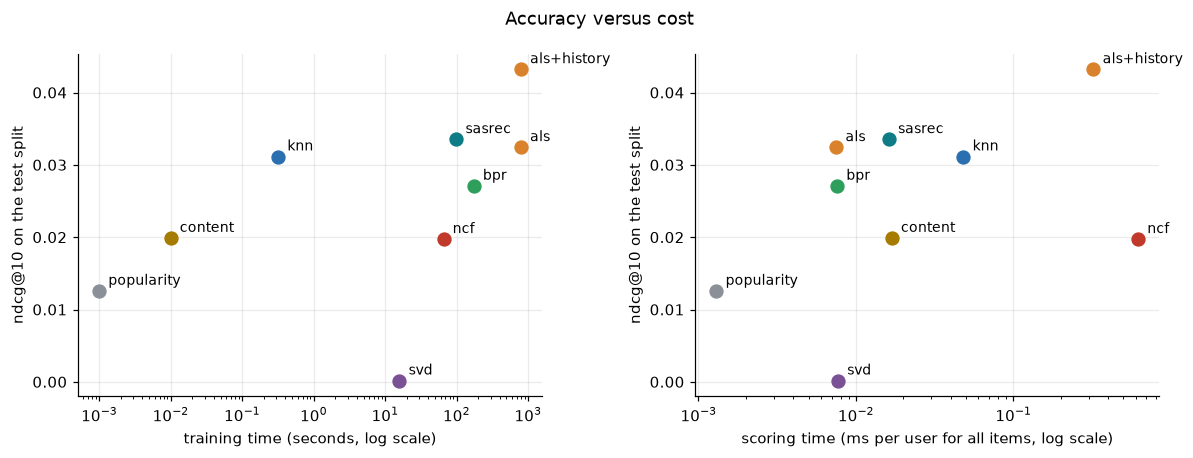

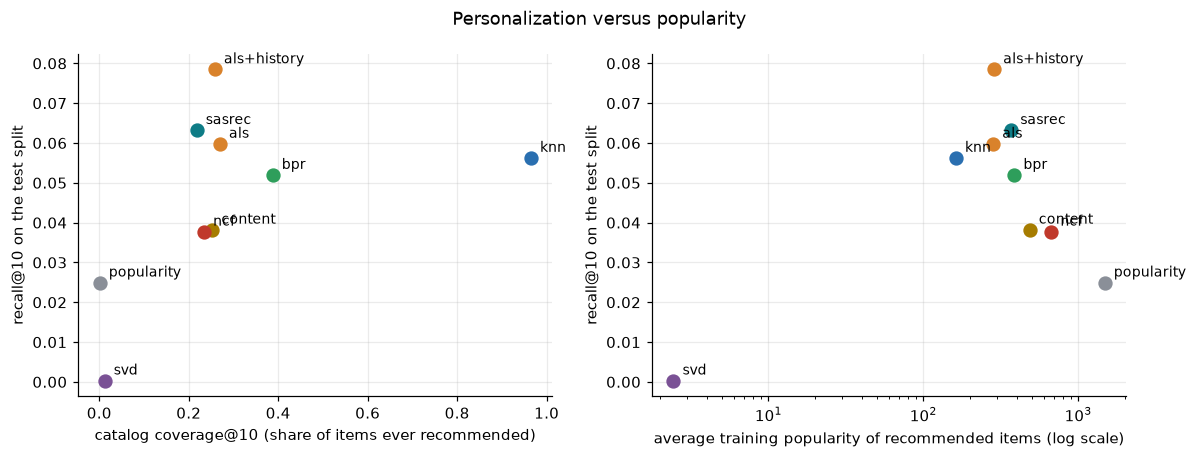

In [65]:
fig = cost_scatter(cost); fig.savefig(FIG / "results_cost.png", dpi=150); plt.show()
fig = tradeoff_scatter(cost); fig.savefig(FIG / "results_tradeoff.png", dpi=150); plt.show()

Cost: training times range from 0.0 s (popularity) to 796 s (als), and scoring from 0.007 ms per user (als) to 0.62 ms (ncf). als+history reaches the top accuracy with a 796 s fit and 0.323 ms per user. ncf needs 83 times the scoring time of als and 1.9 times that of als+history for a much lower NDCG@10 (0.0197 against 0.0432). Personalization versus popularity: popularity recommends the same few items to everyone (coverage@10 0.0008, Gini 0.9996, average training popularity of recommended items 1483), while als+history covers 0.258 of the catalog (Gini 0.941, average popularity 286). The most diverse model is knn (coverage@10 0.965); the models are not equally good at accuracy and diversity, so accuracy alone would hide the popularity trade-off.

### Back to the proposal: does model complexity pay off?

The proposal asks whether neural and transformer recommenders justify their cost over classical matrix factorization at this data scale. NeuMF's NDCG@10 (0.0197) is significantly below ALS (0.0324) and significantly below BPR (0.0271), and it needs 83 times ALS's scoring time. SASRec's (0.0335) is not significantly different from ALS; als+history is significantly above sasrec (NDCG@10 difference 0.0097, paired bootstrap p < 0.001). SASRec fits in 99 s against 796 s for ALS, has 3.4 million parameters against 30.8 million, and scores at 0.016 ms per user (ALS: 0.007 ms as trained, 0.323 ms when every user is scored from their history). Tuning effort was of the same order for all of them (runs: ncf 12, sasrec 19, als 13, bpr 17, knn 9), but each model was trained once, so differences the paired bootstrap cannot separate should not be read as an ordering. **Answer: neither neural model is significantly better than the best classical model (als, 0.0324), so on this data the extra complexity did not buy accuracy; the most accurate model overall is als+history, a classical matrix factorization.**

The proposal also anticipated that the popularity baseline would be surprisingly competitive on raw accuracy while performing poorly on coverage and long-tail items. The coverage and long-tail half held: popularity covers 0.0008 of the catalog at 10, and its Recall@10 is 0.0393 on head items but 0.0000 on mid and 0.0000 on tail items. The accuracy half held only in part: popularity's Recall@10 (0.0249) is far below the leaders (als+history reaches 3.1 times as much, sasrec 2.5 times), so it is not competitive with them, though ncf and content are less than twice as accurate as it (ncf 1.5 times, content 1.5 times), so for the weaker personalised models the baseline is a hard bar to clear.

### Rating prediction (RMSE)

In [66]:
rows = []
for name in ORDER:
    p = RESULTS_DIR / f"{name}_final.json"
    if p.exists():
        r = json.loads(p.read_text())
        if r["test"]["rmse"] is not None:
            rows.append({"model": name, "val_rmse": r["val"]["rmse"], "test_rmse": r["test"]["rmse"], "test_mae": r["test"]["mae"]})
pd.DataFrame(rows).round(4)

,model,val_rmse,test_rmse,test_mae
0,popularity,1.1795,1.2500,0.9395
1,svd,1.0968,1.1785,0.8334


Only popularity (shrunk item mean) and SVD predict ratings. SVD has the lower test RMSE, 1.1785 against 1.2500 (validation 1.0968 against 1.1795). For scale, predicting the global mean gives 1.2949. The held-out test ratings are more spread out than the training ratings (standard deviation 1.29 against 1.17).

# Part 5. Where the models fail: popularity slices, activity slices, cold items and cold-start users

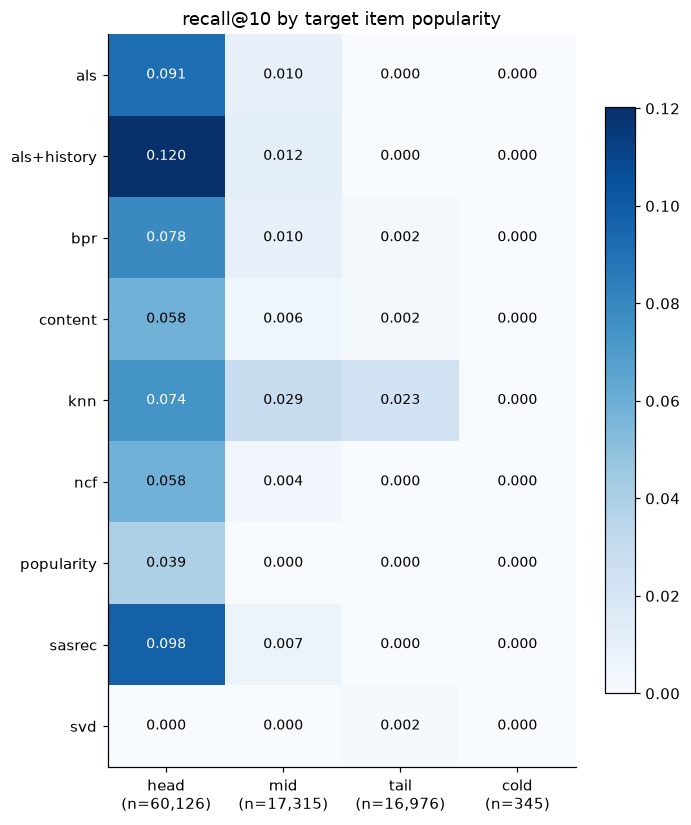

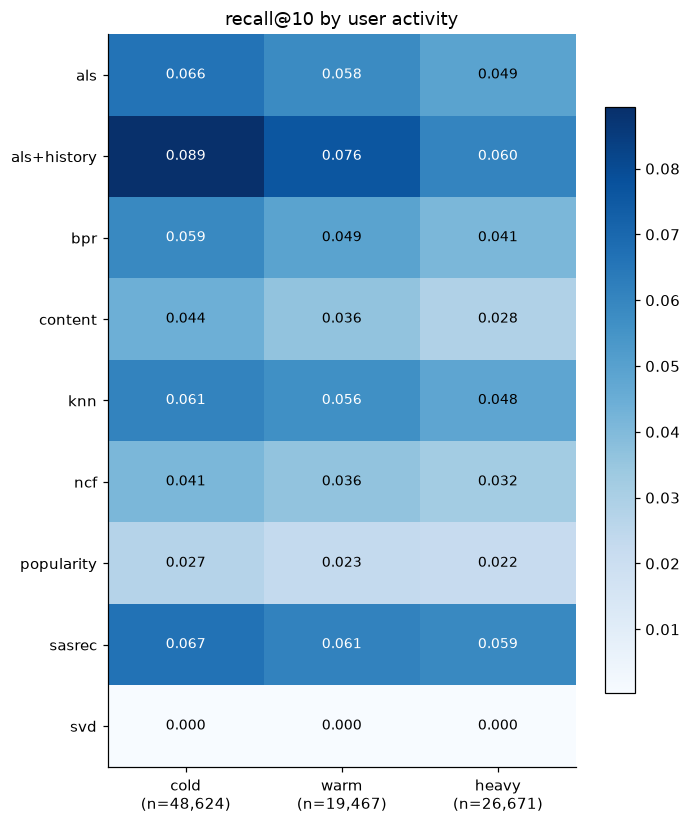

In [67]:
from recsys.plots import slice_heatmap, cold_start_curve
for kind in ("item_bin", "user_bin"):
    ax = slice_heatmap(RESULTS_DIR, kind, "recall@10"); ax.figure.savefig(FIG / f"slices_{kind}.png", dpi=150); plt.show()

63.4% of test purchases are of head items (the top 20% by training popularity), 18.3% mid, 17.9% tail and 0.4% items never seen in training. Popularity can only score on head items (Recall@10 0.0393 there, 0.0000 on mid and 0.0000 on tail items). The best model on tail items is knn (Recall@10 0.0230). Models with essentially no skill on tail items: popularity, als, als+history, ncf and sasrec. By user activity (second chart) the cold, warm and heavy thirds are shown for every model.

In [68]:
rows = []
for name in ORDER:
    p = RESULTS_DIR / f"{name}_final.json"
    if p.exists():
        c = json.loads(p.read_text())["test_slices"]["item_bin"]["cold"]
        rows.append({"model": name, "recall@10 on never-seen items": c["recall@10"], "n": c["n"]})
pd.DataFrame(rows).round(4)

,model,recall@10 on never-seen items,n
0,popularity,0.0,345
1,knn,0.0,345
2,als,0.0,345
3,svd,0.0,345
4,bpr,0.0,345
5,ncf,0.0,345
6,sasrec,0.0,345
7,content,0.0,345


The 345 test purchases of items that never appeared in training: no model has any of them in its top 10. A model that reads item text can in principle reach them. Where the held-out items actually rank (median rank, share in the top 100 and in the top 1,000): popularity: median rank 25,606 of 25,612, 0.0% in the top 100, 0.0% in the top 1,000; knn: median rank 25,606 of 25,612, 0.0% in the top 100, 0.0% in the top 1,000; sasrec: median rank 25,554 of 25,612, 0.0% in the top 100, 0.0% in the top 1,000; content: median rank 16,832 of 25,612, 0.0% in the top 100, 1.4% in the top 1,000. These items have no popularity prior and no neighbours, so they rarely outrank items with any interaction history.

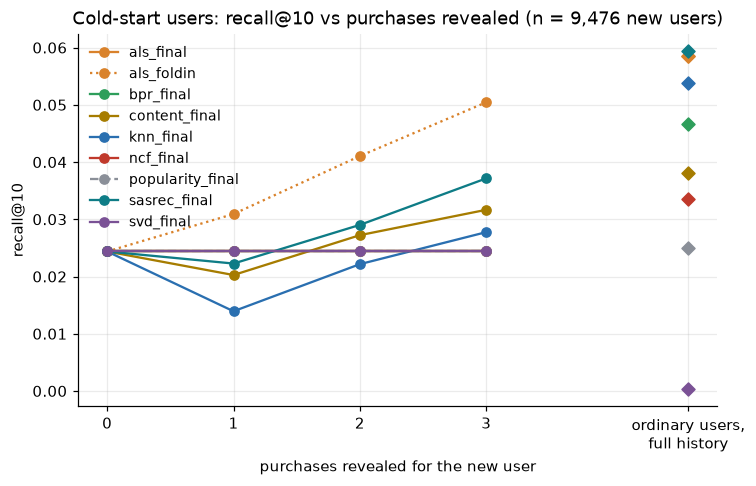

In [69]:
ax = cold_start_curve(RESULTS_DIR / "processed_coldstart"); ax.figure.savefig(FIG / "cold_start_curve.png", dpi=150); plt.show()

New users are 9,476 users held out of training entirely; the model sees only their first n purchases and must rank their last purchase. Recall@10 for n = 0, 1, 2, 3: popularity is flat at 0.0244, the floor (n = 0 means no information, so every model falls back to popularity). knn 0.0244 / 0.0139 / 0.0222 / 0.0278 (passes the floor at n = 3); als 0.0244 / 0.0244 / 0.0244 / 0.0244 (never above the floor); svd 0.0244 / 0.0244 / 0.0244 / 0.0244 (never above the floor); bpr 0.0244 / 0.0244 / 0.0244 / 0.0244 (never above the floor); ncf 0.0244 / 0.0244 / 0.0244 / 0.0244 (never above the floor); sasrec 0.0244 / 0.0223 / 0.0290 / 0.0371 (passes the floor at n = 2); content 0.0244 / 0.0203 / 0.0272 / 0.0317 (passes the floor at n = 2). als, svd, bpr and ncf stay exactly on the floor because they learn a vector per user during training and have none for a new user; they cannot use the revealed purchases. Folding the revealed purchases into ALS with the item factors fixed lifts it to 0.0244 / 0.0309 / 0.0411 / 0.0504. With a single purchase, knn, sasrec and content score below the floor, so they do worse than showing best-sellers. With three purchases the best model is als with fold-in (0.0504, 2.1 times the floor). For comparison, the other 90% of users, with their full history, get Recall@10 0.0595 from sasrec on this data. Revealed purchases help only the models that can use them.

# Part 6. The recommender in use

The recommender in use. We use als+history, the most accurate model with a saved copy (test NDCG@10 0.0432). Given a user it returns ten products; it sees everything known about the user except their held-out last purchase, and never recommends something they already own. Below: a user whose real next purchase is in the top ten, and one where the model misses, shown with titles.

In [70]:
import importlib
from recsys.demo import demo
from recsys.models.base import Recommender

BASE_MODEL = "als"
saved = RESULTS_DIR / "models" / "als_demo.pkl"
if saved.exists():
    model = Recommender.load(saved)
else:   # no saved copy next to the notebook: refit it (minutes)
    module = importlib.import_module(f"recsys.models.{BASE_MODEL}")
    cls = next(c for _, c in vars(module).items() if isinstance(c, type) and issubclass(c, Recommender) and c is not Recommender and c.__module__ == module.__name__)
    model = cls(**FINAL_CONFIGS[BASE_MODEL]); model.fit(data)
    if "+history" in "als+history":
        model.foldin_all = True   # score every user from the history they are given

ranks = np.load(RESULTS_DIR / "per_user" / "als_foldall.npz")["rank_test"]
rng = np.random.default_rng(7)
long_history = np.flatnonzero(users["n_train"].to_numpy() >= 8)
hit = int(rng.choice(long_history[ranks[long_history] <= 10]))
miss = int(rng.choice(long_history[ranks[long_history] > 1000]))
print("=== a user whose next purchase the model finds ==="); demo(model, data, hit)
print("\n=== a user it misses ==="); demo(model, data, miss)

=== a user whose next purchase the model finds ===
user AHSQC5U3NXE3AQVY46CKWE554VAQ (user_idx 89174), 16 known purchases; latest 5:
                                                                           title         store     price pop_bin
                             Ike amiibo - Japan Import (Super Smash Bros Series)      Nintendo 25.000000    head
Amazon Basics Carrying Case for Nintendo - New 3DS XL, 3DS XL - Black (Officiall Amazon Basics       NaN    head
                           Robin Amiibo - Japan Import (Super Smash Bros Series)      Nintendo 26.400000    head
                                      Fire Emblem Fates: Conquest - Nintendo 3DS      Nintendo 42.250000    head
                 Fire Emblem Fates: Birthright - Nintendo 3DS Birthright Edition      Nintendo 44.990002    head 

top 10 recommendations from als+history:
 rank                                                                            title       store      price pop_bin
    1                       

# Part 7. Limitations and notes

- **Single run per model.** Each final model was trained once with one seed. The intervals above come from resampling users, not from retraining; training on the Apple GPU (MPS) is not guaranteed to be bit-for-bit reproducible, and we did not repeat runs with other seeds.
- **Unequal tuning effort.** Runs per model: popularity 1, knn 9, als 13, svd 24, bpr 17, ncf 12, sasrec 19, content 13. Every choice used the validation split only; the test split was used once per model for reporting. The sweep timings were measured while other jobs shared the machine; the final-run timings in the cost table were measured alone.
- **The test protocol favours models that read the history.** The test item is scored after the validation purchase. KNN, SASRec and the content model read it from the history they are given; models with a learned vector per user (ALS, BPR, NeuMF, SVD) do not. Validation minus test NDCG@10: popularity +0.0010, knn +0.0067, als +0.0200, bpr +0.0128, ncf +0.0052, sasrec +0.0030, content +0.0026. The als+history row separates this effect from model quality for ALS. It was added after seeing the gap (not pre-specified); BPR, NeuMF and SVD have no cheap equivalent, so their test numbers are, to the same degree, understated relative to history-based models.
- **Per-user time split.** Each user's last two interactions are held out, rather than one global cut-off date, so a test event can pre-date other users' training events. This is the protocol in the approved proposal.
- **Dense core only.** The 5-core filter keeps 17.9% of interactions and 3.4% of users, so the results describe users with at least five reviews, not typical Amazon shoppers.
- **Cold-start users are simulated.** New users are users held out of training, and the target is their last purchase, which can be many purchases after the revealed ones; a real session would predict the next item.
- **One dataset.** A single Amazon category; ratings are 64% five-star, so rating signals are weak, and results may differ on other domains.

### Reference
- Krichene, W. and Rendle, S. (2020). On Sampled Metrics for Item Recommendation. Proceedings of the 26th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD '20).